# Batch Quality and Equipment Reliability: complete analysis

This single notebook runs the whole analysis in order: data audit and cleaning, exploratory
analysis, the batch classifier, equipment reliability, process control and trend, the risk view
and back-test, and the optional demand forecast. Each section is explained in its own text cell.
It reproduces the results in reports/tables and reports/figures.

# STAGE 1 — DATA CLEANING

# 01 Data audit and cleaning

**Purpose.** This notebook checks the four raw files, cleans and links them, and
verifies every headline claim in the proposal (version 3.0) against the data.
Nothing in the proposal is taken on trust: each claim is either confirmed, or
flagged with the value the data actually shows.

**Sources.** Batch production records (60,000 rows), equipment maintenance records
(60,000 rows, one per batch), sales transactions (150,000 rows) and inventory
movements (162,000 rows).

**Output.** Processed Parquet tables in `data/processed/`, and the quality-check
register in `reports/tables/data_quality_register.csv`.

In [335]:
# Setup: make the project package importable and apply the shared plot style.
import sys
import warnings
from pathlib import Path

import os


def _find_project_root() -> Path:
    """Locate the project folder (the one containing src/config.py).

    Checks the BQ_PROJECT_ROOT environment variable first, then the current folder
    and each of its parents, so the notebook runs from any working directory.
    """
    env_root = os.environ.get("BQ_PROJECT_ROOT")
    if env_root:
        return Path(env_root).resolve()
    here = Path.cwd().resolve()
    for candidate in [here, *here.parents]:
        if (candidate / "src" / "config.py").exists():
            return candidate
    raise FileNotFoundError(
        "Could not find the project folder (the one containing src/config.py). "
        "Open the notebook from inside the project, or set BQ_PROJECT_ROOT to its path."
    )


ROOT = _find_project_root()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from src.config import TARGET_COL, MIN_RECALL, MIN_PRECISION, ROC_AUC_TARGET
from src.data_io import load_processed
from src.plotting import set_plot_style, save_figure, PRIMARY, ALERT, ACCENT, POSITIVE, NEUTRAL

warnings.filterwarnings("ignore")
set_plot_style()
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 220)
pd.set_option("display.max_colwidth", 80)
print("Project root:", ROOT)







# Import standard-library tools used for file paths, SQL, warnings, and utilities.
import os, sys, sqlite3, warnings, json, math                               # system, SQL, warning and maths utilities
from pathlib import Path                                                    # file-path handling

# Import data handling and plotting libraries.
import numpy as np                                                          # numerical arrays
import pandas as pd                                                         # data tables (DataFrames)
import matplotlib.pyplot as plt                                             # plotting
import seaborn as sns                                                       # statistical charts

# Import tools for splitting data, preprocessing features, and building pipelines.
from sklearn.model_selection import train_test_split                        # split data into training and test sets
from sklearn.compose import ColumnTransformer                               # apply different preprocessing to different columns
from sklearn.pipeline import Pipeline                                       # chain preprocessing steps
from sklearn.preprocessing import OneHotEncoder, StandardScaler             # encode categories; standardise numbers
from sklearn.impute import SimpleImputer                                    # fill missing values

# Import evaluation metrics for classification and regression models.
from sklearn.metrics import (classification_report, confusion_matrix, precision_score,  # model evaluation metrics
                             recall_score, f1_score, roc_auc_score, average_precision_score,
                             mean_absolute_error, mean_squared_error, r2_score)

# Import candidate machine-learning models and dimensionality-reduction tools.
from sklearn.linear_model import LogisticRegression, Ridge                  # linear models
from sklearn.tree import DecisionTreeClassifier                             # decision tree model
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor, GradientBoostingClassifier, IsolationForest  # tree-ensemble models
from sklearn.neural_network import MLPClassifier                            # simple neural-network classifier
from sklearn.decomposition import PCA                                       # principal component analysis
from IPython.display import display
from src.config import TARGET_COL, MIN_RECALL, MIN_PRECISION, ROC_AUC_TARGET
from src.data_io import load_processed
from src.plotting import set_plot_style, save_figure, PRIMARY, ALERT, ACCENT, POSITIVE, NEUTRAL
set_plot_style()


# Set a fixed random seed so random operations are reproducible.
RANDOM_STATE = 42                                                           # fixed seed used throughout
np.random.seed(RANDOM_STATE)                                                # make NumPy random results repeatable

# Set a default size for plots.
plt.rcParams['figure.figsize'] = (10, 5)                                    # default chart size


Project root: /Users/apple/Desktop/Capstone-Project


## 1. Load the raw files

The raw files are read exactly as supplied. They are never edited in place, so the
analysis can always be traced back to the original extract.

In [337]:
from src.config import RAW_FILES, DATA_RAW
from src.data_io import load_raw

print("Raw files present:", {k: (DATA_RAW / v).exists() for k, v in RAW_FILES.items()})
raw = {key: load_raw(key) for key in RAW_FILES}
summary = pd.DataFrame({k: {"rows": len(v), "columns": v.shape[1]} for k, v in raw.items()}).T
display(summary)
display(raw["batch"].head(3))

Raw files present: {'batch': True, 'maintenance': True, 'sales': True, 'inventory': True}


,rows,columns
batch,60000,30
maintenance,60000,16
sales,150000,23
inventory,162000,10


,batch_id,drug_name,dosage_form,manufacturing_section,production_start,batch_size,batch_size_unit,equipment_id,equipment_name,equipment_age_days,maintenance_days_ago,upstream_equipment_id,downstream_equipment_id,ahu_id,operator_id,operator_experience_years,temp_avg,temp_variance,pressure_avg,pressure_variance,humidity_avg,production_hours,raw_material_quality,target_yield,actual_yield,assay_result_purity,impurity_level,dissolution_time_min,batch_passed,rejection_reason
0,TOT-07-0001,Totomol,Tablet,Oral Solids,2007-01-02,250,kg,LAL/TAB/006,35 STN Compression Machine,1695,78,LAL/TAB/012,LAL/TAB/008,LAL/AHU-G-07,EMP-0388,3,23.71,0.149,1.001,0.0233,44.0,26.7,99.6,95.0,99.79,100.69,0.098,17.26,1,NaN
1,ACM-07-0001,Acemol,Tablet,Oral Solids,2007-01-03,250,kg,LAL/TAB/006,35 STN Compression Machine,1696,79,LAL/TAB/012,LAL/TAB/008,LAL/AHU-G-07,EMP-0319,8,22.11,0.335,1.006,0.0729,47.1,21.4,99.8,95.0,99.21,99.55,0.104,16.67,1,NaN
2,ACM-07-0002,Acemol,Tablet,Oral Solids,2007-01-03,200,kg,LAL/TAB/006,35 STN Compression Machine,1696,79,LAL/TAB/012,LAL/TAB/008,LAL/AHU-G-07,EMP-0413,2,22.59,0.124,NaN,0.0728,48.7,19.6,99.6,95.0,98.62,100.18,0.066,15.06,1,NaN


## 2. Missing values in the batch file

Missing values are reported before any cleaning. Process readings are missing in
roughly one to two percent of rows, and dissolution time is missing for about a
quarter of batches. Dissolution is a release test, so it is not a predictor; the
missingness is kept as a flag rather than imputed.

Columns with missing values: 11 of 30


,missing_percent
rejection_reason,96.88
dissolution_time_min,25.10
humidity_avg,1.44
temp_variance,1.32
pressure_variance,1.19
raw_material_quality,1.14
pressure_avg,0.98
temp_avg,0.74
impurity_level,0.50
production_hours,0.48


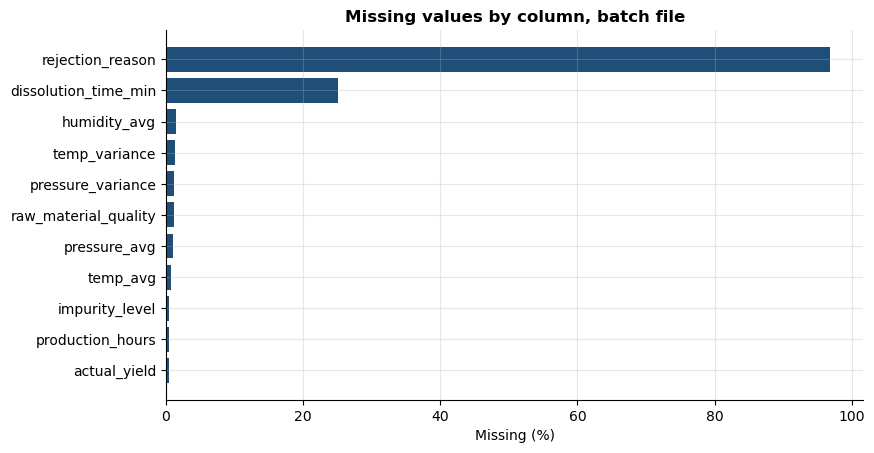

In [339]:
# Share of missing values for each column in the batch file, highest first.
missing = raw["batch"].isna().mean().sort_values(ascending=False)
missing = missing[missing > 0]
print(f"Columns with missing values: {len(missing)} of {raw['batch'].shape[1]}")
display(missing.mul(100).round(2).rename("missing_percent").to_frame())

fig, ax = plt.subplots(figsize=(9, 4.8))
ax.barh(missing.index[::-1], missing.values[::-1] * 100, color=PRIMARY)
ax.set_xlabel("Missing (%)")
ax.set_title("Missing values by column, batch file")
save_figure(fig, "01_missingness_batch")
plt.show()

**Output:** 11 of 30 batch columns have gaps. `rejection_reason` is 96.9% empty because only failed batches have one, and dissolution time is 25.1% empty. Process readings are missing in only 0.4–1.4% of rows. **Chart:** horizontal bars of the missing share per column, the two long bars being rejection reason and dissolution.

## 3. Run the cleaning pipeline and the quality register

The cleaning step links the batch and maintenance files one-to-one, checks each
shared field, harmonises the rejection labels, pseudonymises operator identifiers,
and records every check in a register. Each check is marked PASS, FLAG or INFO.
A FLAG is a finding that needs attention, not a hidden error.

In [342]:
import importlib, src.cleaning
importlib.reload(src.cleaning)
from src.cleaning import run_cleaning

# Run the full cleaning step. Processed tables are written to data/processed/.
tables = run_cleaning(save=True)
register = tables["quality_register"]
print(f"Quality checks run: {len(register)}")
print(register["status"].value_counts().to_string())
display(register)

Quality checks run: 45
status
PASS    33
INFO    10
FLAG     2


,area,check,observed,expected,status,note
0,Batch file,Row count,60000,"60,000",PASS,
1,Batch file,Batch IDs unique,60000,equal to row count,PASS,
2,Maintenance file,Row count,60000,"60,000",PASS,
3,Linkage,Batch IDs match maintenance IDs,100.00%,100%,PASS,
4,Linkage,Agreement: equipment_id,100.00%,100%,PASS,
5,Linkage,Agreement: equipment_age_days,100.00%,100%,PASS,
6,Linkage,Agreement: maintenance_days_ago,100.00%,100%,PASS,
7,Linkage,Agreement: batch_size,100.00%,100%,PASS,
8,Linkage,Agreement: operator_experience_years,100.00%,100%,PASS,
9,Linkage,Agreement: batch_passed,100.00%,100%,PASS,


**Output:** 45 quality checks ran: 33 PASS, 10 INFO, 2 FLAG. The two flags are the 6,045 stock movements recorded for cancelled sales and the missing opening stock.

## 4. Verify the proposal's claims

The table below sets each proposal claim against the value observed in the data.
One claim does not match the data: the rejection-reason agreement between files.
The data gaps the proposal describes (no opening stock, no repair times) are confirmed.

In [345]:
batches = tables["batches"]
sales_clean = tables["sales"]


def observed(check_text: str) -> str:
    """Return the observed value of the quality register row whose check text matches."""
    row = register[register["check"].str.contains(check_text, regex=False)].iloc[0]
    return str(row["observed"])


failed = batches[batches[TARGET_COL] == 1]
claims = pd.DataFrame(
    [
        ("Overall failure rate 3.1% (1,875 failed batches)",
         f"{batches[TARGET_COL].mean():.2%} ({int(batches[TARGET_COL].sum()):,})", "Confirmed"),
        ("Critical maintenance batches fail at 6.9%",
         f"{batches.loc[batches.maintenance_status == 'Critical', TARGET_COL].mean():.2%}", "Confirmed"),
        ("Critical maintenance applies to 476 batches",
         f"{(batches.maintenance_status == 'Critical').sum():,}", "Confirmed"),
        ("Dissolution time missing for about 25% of batches",
         f"{batches.dissolution_time_min.isna().mean():.2%}", "Confirmed"),
        ("Assay failures are 29% of all failures",
         f"{(failed.failure_mode == 'Assay').mean():.1%}", "Confirmed"),
        ("Dissolution failures are 18% of all failures",
         f"{(failed.failure_mode == 'Dissolution').mean():.1%}", "Confirmed"),
        ("Batch and maintenance IDs match 100%", observed("Batch IDs match maintenance IDs"), "Confirmed"),
        ("Batch date equals maintenance date on every batch",
         observed("Batch date equals maintenance date"), "Confirmed"),
        ("Equipment, section and pass/fail agree across the two batch files",
         observed("Agreement: equipment_id") + " (equipment)", "Confirmed"),
        ("Rejection reason agrees on only about 3% of rows",
         observed("Rejection reason agreement"), "NOT CONFIRMED: files agree on every row"),
        ("Sales and inventory join on Reference ID for all 150,000 sales",
         observed("Sale_Out movements linked"), "Confirmed"),
        ("300 products, 4 branches, 30 suppliers in sales",
         "300 / 4 / 30", "Confirmed"),
        ("Inventory data has no opening stock (stock on hand cannot be verified)",
         observed("Opening stock available"), "Confirmed as a gap"),
    ],
    columns=["Proposal claim", "Observed in the data", "Status"],
)
display(claims.set_index("Proposal claim"))

,Observed in the data,Status
Proposal claim,,
"Overall failure rate 3.1% (1,875 failed batches)","3.12% (1,875)",Confirmed
Critical maintenance batches fail at 6.9%,6.93%,Confirmed
Critical maintenance applies to 476 batches,476,Confirmed
Dissolution time missing for about 25% of batches,25.09%,Confirmed
Assay failures are 29% of all failures,29.1%,Confirmed
Dissolution failures are 18% of all failures,18.2%,Confirmed
Batch and maintenance IDs match 100%,100.00%,Confirmed
Batch date equals maintenance date on every batch,100.00%,Confirmed
"Equipment, section and pass/fail agree across the two batch files",100.00% (equipment),Confirmed


**Output:** 12 of 13 proposal claims are confirmed. The exception is rejection-reason agreement: the proposal says about 3%, but the two files agree on 100% of rows.

## 5. Harmonising the failure modes

The raw rejection file uses fourteen labels, several of which describe the same
failure in different words (for example, "Visible particulate matter" and "Foreign
matter / visible particles"). The labels are grouped into ten failure modes so that
the Pareto analysis is readable. Every failed batch is kept; none is dropped.

,raw_label,failure_mode
0,Assay out of specification,Assay
1,Blend uniformity failure,Blend uniformity
2,Phase separation / homogeneity failure,Blend uniformity
3,Dissolution failure,Dissolution
4,Microbial limit failure,Microbial
5,Bacterial endotoxin above limit,Microbial
6,Sterility test failure,Microbial
7,Foreign matter / visible particles,Particulates
8,Visible particulate matter,Particulates
9,Hardness / friability out of specification,Physical strength


Failed batches with a harmonised mode: 1,875 of 1,875


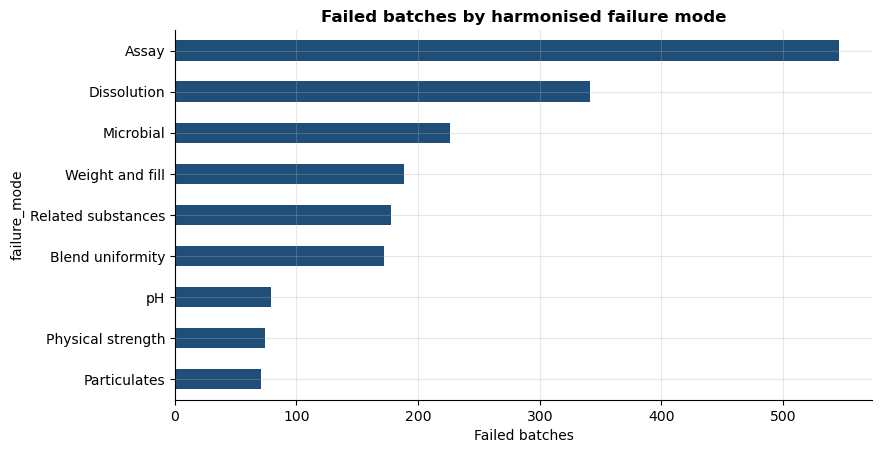

In [348]:
from src.cleaning import FAILURE_MODE_MAP

# The mapping used for harmonisation, grouped by failure mode.
mapping = pd.DataFrame(sorted(FAILURE_MODE_MAP.items(), key=lambda kv: kv[1]),
                       columns=["raw_label", "failure_mode"])
display(mapping)

modes = failed["failure_mode"].value_counts()
print(f"Failed batches with a harmonised mode: {modes.sum():,} of {len(failed):,}")
fig, ax = plt.subplots(figsize=(9, 4.8))
modes.sort_values().plot.barh(ax=ax, color=PRIMARY)
ax.set_xlabel("Failed batches")
ax.set_title("Failed batches by harmonised failure mode")
save_figure(fig, "02_failure_modes")
plt.show()

**Output:** 15 raw labels are grouped into harmonised failure modes, and all 1,875 failed batches get one. **Chart:** failures per mode; Assay (546) and Dissolution (341) are the longest bars.

## 6. Sales and inventory reconciliation

Sales and inventory are analysed separately from production, because the proposal
states that the two groups share no key. Sales have no cancelled-order stock
adjustment: the inventory file still records stock leaving for cancelled orders,
which is flagged in the register. Cancelled orders are excluded from demand.

In [351]:
# Reconcile the inventory Sale_Out movements against the sales file.
inventory = tables["inventory"]
out = inventory[inventory["Movement_Type"] == "Sale_Out"]
recon = pd.DataFrame(
    {
        "Sale_Out movements": [len(out)],
        "Linked to a sale": [out["Reference_ID"].isin(sales_clean["Sale_ID"]).sum()],
        "Quantity matches sale": [
            (out.set_index("Reference_ID")["Quantity_Change"].abs()
             == sales_clean.set_index("Sale_ID")["Quantity"].reindex(out["Reference_ID"]).values).sum()
        ],
        "Recorded against cancelled orders": [
            sales_clean.set_index("Sale_ID").loc[out["Reference_ID"], "is_cancelled"].sum()
        ],
    }
)
display(recon.T.rename(columns={0: "count"}))

,count
Sale_Out movements,150000
Linked to a sale,150000
Quantity matches sale,150000
Recorded against cancelled orders,6045


**Output:** all 150,000 sale-out movements link to a sale and match its quantity. 6,045 of them belong to cancelled orders, so stock was deducted for goods that never left (fixed in 1.9).

## 7 Outlier review for all four datasets

In [354]:
# Flag values outside 1.5 x IQR for the key numeric columns of each dataset (reported, not removed).
checks = [("Batch", tables["batches"], c) for c in ["actual_yield", "assay_result_purity", "production_hours", "batch_size",
                                                     "operator_experience_years", "maintenance_days_ago"]]
checks += [("Sales", tables["sales"], c) for c in ["Quantity", "Unit_Price_KES", "Net_Amount_Excl_VAT_KES"]]
checks += [("Inventory (receipts)", tables["inventory"][tables["inventory"]["Quantity_Change"] > 0], "Quantity_Change")]
rows = []                                                                   # one row per column checked
for source, df, col in checks:
    q1, q3 = df[col].quantile([0.25, 0.75])                                 # quartiles
    low, high = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)                  # 1.5 x IQR limits
    outside = ((df[col] < low) | (df[col] > high)).sum()                    # values outside the limits
    rows.append([source, col, low, high, outside, 100 * outside / df[col].notna().sum()])
outliers = pd.DataFrame(rows, columns=["Dataset", "Column", "Lower limit", "Upper limit", "Outside", "% outside"])
display(outliers.round(2))                                                  # outlier table

,Dataset,Column,Lower limit,Upper limit,Outside,% outside
0,Batch,actual_yield,93.73,101.78,95,0.16
1,Batch,assay_result_purity,96.41,103.61,1950,3.25
2,Batch,production_hours,-7.65,44.75,2189,3.67
3,Batch,batch_size,-200.00,600.00,7948,13.25
4,Batch,operator_experience_years,-9.50,26.50,1319,2.20
5,Batch,maintenance_days_ago,-49.50,138.50,161,0.27
6,Sales,Quantity,-17.50,34.50,15629,10.42
7,Sales,Unit_Price_KES,-8412.50,16087.50,21495,14.33
8,Sales,Net_Amount_Excl_VAT_KES,-76125.00,135675.00,19984,13.32
9,Inventory (receipts),Quantity_Change,-500.00,1100.00,0,0.00


**Explanation**
- **Batch file:**
  - Yield has **95** outliers (0.16%), all very poor batches.
  - Assay purity has **1,950** (3.25%). These are real quality signals, since out-of-range batches fail far more often (Stage 2, chart D).
  - Production hours have **2,189** (3.67%) long runs.
  - Batch size has **7,948**, but these are not errors: the column mixes kilograms and litres.
  - Operator experience has **1,319** very experienced operators, and days since maintenance has **161** long gaps (the Critical equipment).
- **Sales:**
  - Quantity has **15,629** outliers (10.4%), which are bulk orders up to 400 units.
  - Unit price has **21,495** (14.3%) and net value **19,984**. These are expensive items, mainly Equipment.
- **Inventory:** **0** outliers. Every delivery is one of six fixed lot sizes.
- **Decision:** every outlier is a real business or quality value, so **none is removed**.

## 1.9 Valid stock movements and stock rebuilt from zero
1. Stock movements recorded for **cancelled** orders are removed, because no goods left the shelf.
2. The supplier code missing on sale-out movements is filled **from the linked sale**, not with the most common supplier.

Stock is then rebuilt per branch and product from an opening balance of zero, and reconciled.

In [357]:
# Remove movements for cancelled orders and fill missing supplier codes from the linked sale.
cancelled_ids = tables["sales"].loc[tables["sales"]["is_cancelled"] == 1, "Sale_ID"]  # cancelled orders
stock_moves = tables["inventory"][~tables["inventory"]["Reference_ID"].isin(cancelled_ids)].copy()  # valid movements
missing_supplier = stock_moves["Supplier_ID"].isna()                        # sale-outs have no supplier code
supplier_of_sale = tables["sales"].set_index("Sale_ID")["Supplier_ID"]      # supplier recorded on each sale
stock_moves.loc[missing_supplier, "Supplier_ID"] = stock_moves.loc[missing_supplier, "Reference_ID"].map(supplier_of_sale)
print(f"Movements removed (cancelled orders): {len(tables['inventory']) - len(stock_moves):,}")
print(f"Supplier codes filled from the sale: {missing_supplier.sum():,}; still missing: {stock_moves['Supplier_ID'].isna().sum()}")

# Rebuild stock on hand: opening stock 0 on 1 Jan 2014, then add every movement in date order.
stock_moves = stock_moves.sort_values(["Movement_Date", "Movement_ID"])     # time order
stock_moves["stock_on_hand"] = stock_moves.groupby(["Branch_Code", "Product_ID"])["Quantity_Change"].cumsum()  # running stock
recon = pd.DataFrame({"received": stock_moves[stock_moves["Quantity_Change"] > 0].groupby("Branch_Code")["Quantity_Change"].sum(),
                      "sold": -stock_moves[stock_moves["Quantity_Change"] < 0].groupby("Branch_Code")["Quantity_Change"].sum(),
                      "closing (running stock)": stock_moves.groupby(["Branch_Code", "Product_ID"])["stock_on_hand"].last().groupby("Branch_Code").sum()})
recon["balanced"] = recon["received"] - recon["sold"] == recon["closing (running stock)"]  # both ways must agree
display(recon)                                                              # reconciliation per branch
print(f"Movements leaving stock below zero: {(stock_moves['stock_on_hand'] < 0).mean():.1%}")  # stock-out / back-order signal

Movements removed (cancelled orders): 6,045
Supplier codes filled from the sale: 143,955; still missing: 0


,received,sold,closing (running stock),balanced
Branch_Code,,,,
BR01,2308350,1644898,663452,True
BR02,602400,137654,464746,True
BR03,615600,139127,476473,True
BR04,601200,144562,456638,True


Movements leaving stock below zero: 21.3%


**Explanation**
- **6,045** stock movements belonged to **cancelled** orders and were removed, so cancelled sales no longer reduce stock.
- **143,955** missing supplier codes on sale-outs were filled from the linked sale, leaving **0** missing.
- **Reconciliation:** for all four branches, opening stock (0) + received − sold equals the closing stock from the running total (`balanced = True`). BR01, for example, received 2,308,350 units, sold 1,644,898 and closes at 663,452.
- **21.3%** of movements leave stock below zero. Stock was sold before enough had been received, which shows that back-orders or stock-outs are common (part of this comes from the assumed zero opening stock).
- This table (`stock_moves`) feeds the inventory charts and models below.

## 8. What this notebook established

* The batch and maintenance files are a clean, one-to-one pair. The linkage is complete.
* One proposal statement is not supported by the data: the rejection-reason agreement
  between the two batch files. The files agree on every row. The proposal's date
  conversion is consistent with the ISO dates supplied.
* Inventory has no opening balance, so stock on hand cannot be computed. Stock-out and
  expiry modules remain out of scope, as the proposal states.
* Operator identifiers are pseudonymised before any output is written.

# STAGE 2 — EXPLORATORY DATA ANALYSIS (EDA)

# 02 Exploratory analysis and research questions

**Purpose.** Answer the research questions in proposal section 4 with evidence:
which batches fail, what drives failure, how the failure modes are distributed, and
how the failure rate has changed over time. The sales and inventory data are summarised
at the end, as context for the optional demand module.

All rates are shown with 95 percent Wilson confidence intervals, because the
Critical maintenance group is small and point estimates alone would overstate precision.

In [361]:
# Setup: make the project package importable and apply the shared plot style.
import sys
import warnings
from pathlib import Path

import os


def _find_project_root() -> Path:
    """Locate the project folder (the one containing src/config.py).

    Checks the BQ_PROJECT_ROOT environment variable first, then the current folder
    and each of its parents, so the notebook runs from any working directory.
    """
    env_root = os.environ.get("BQ_PROJECT_ROOT")
    if env_root:
        return Path(env_root).resolve()
    here = Path.cwd().resolve()
    for candidate in [here, *here.parents]:
        if (candidate / "src" / "config.py").exists():
            return candidate
    raise FileNotFoundError(
        "Could not find the project folder (the one containing src/config.py). "
        "Open the notebook from inside the project, or set BQ_PROJECT_ROOT to its path."
    )


ROOT = _find_project_root()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from src.config import TARGET_COL, MIN_RECALL, MIN_PRECISION, ROC_AUC_TARGET
from src.data_io import load_processed
from src.plotting import set_plot_style, save_figure, PRIMARY, ALERT, ACCENT, POSITIVE, NEUTRAL

warnings.filterwarnings("ignore")
set_plot_style()
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 220)
pd.set_option("display.max_colwidth", 80)
print("Project root:", ROOT)

Project root: /Users/apple/Desktop/Capstone-Project


In [362]:
# Load the cleaned tables written by the cleaning step (notebook 01 or the pipeline).
batches = load_processed("batches")
sales = load_processed("sales")
inventory = load_processed("inventory")
print(f"Batches: {len(batches):,} | Sales lines: {len(sales):,} | Inventory movements: {len(inventory):,}")

Batches: 60,000 | Sales lines: 150,000 | Inventory movements: 162,000


## 1. Headline figures

In [364]:
from src.reliability import rate_table, add_bands

headline = pd.Series(
    {
        "Batches": f"{len(batches):,}",
        "Failed batches": f"{int(batches[TARGET_COL].sum()):,}",
        "Failure rate": f"{batches[TARGET_COL].mean():.2%}",
        "Equipment units": batches["equipment_id"].nunique(),
        "Drugs": batches["drug_name"].nunique(),
        "Production years": f"{batches['year'].min()} to {batches['year'].max()}",
    },
    name="value",
)
display(headline.to_frame())

,value
Batches,"60,000"
Failed batches,"1,875"
Failure rate,3.12%
Equipment units,13
Drugs,40
Production years,2007 to 2026


**Output:** the plant ran 60,000 batches across 13 machines and 40 drugs from 2007 to 2026. 1,875 failed (3.12%).

## 2. What drives failure: the main factors

Each panel shows the failure rate for one factor, with its 95 percent interval.
These are unadjusted rates. The proposal correctly warns that maintenance status,
equipment age, operator experience and dosage form are correlated, so these
differences are tested after adjustment in notebooks 03 and 04.

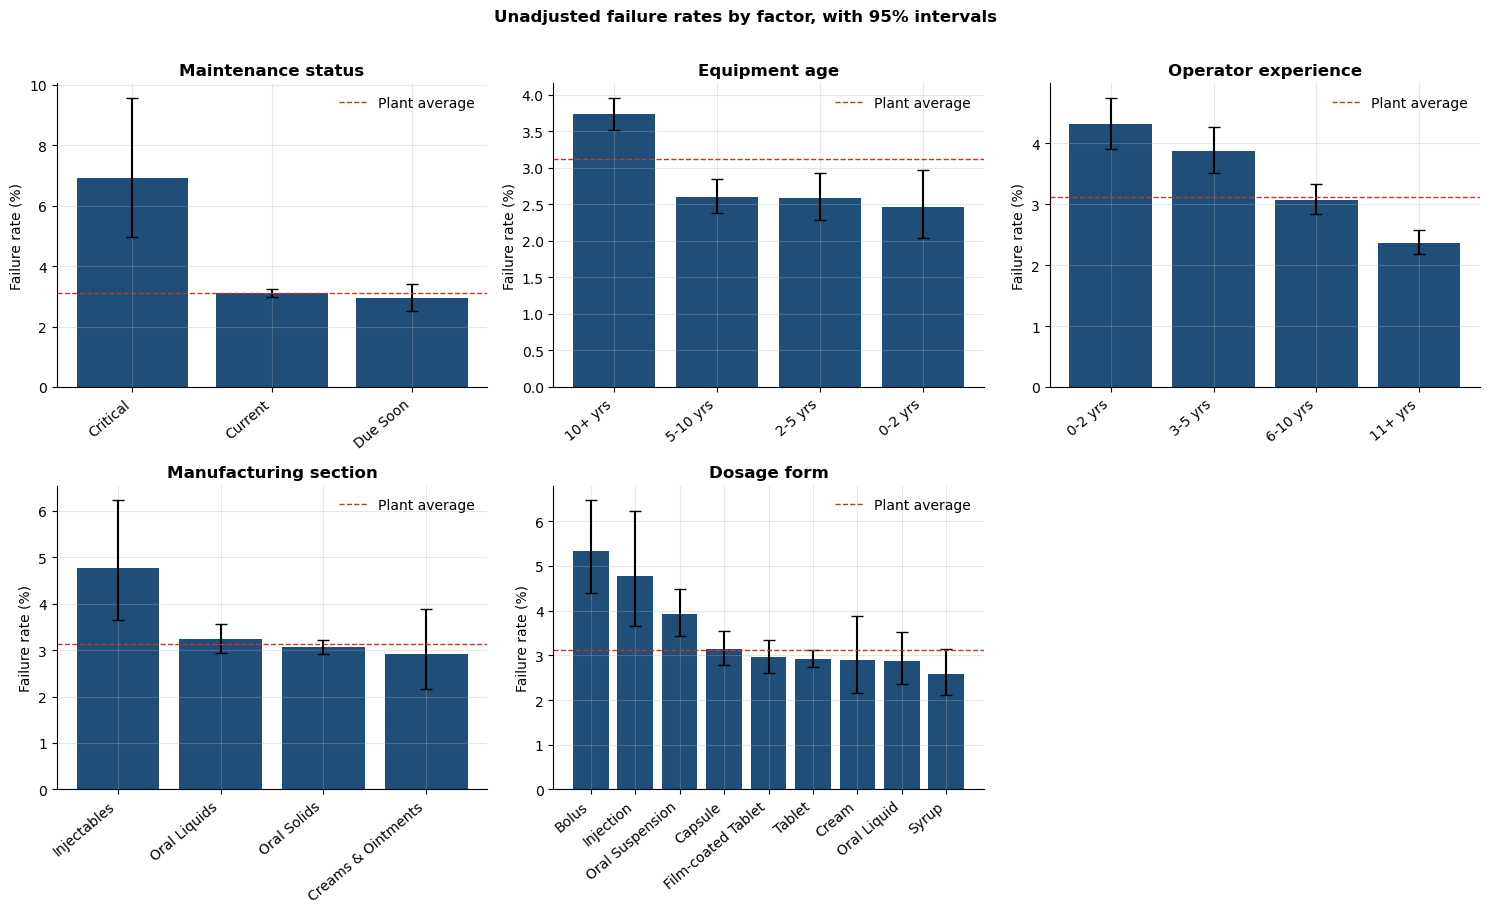

,batches,failures,failure_rate,ci_low,ci_high
maintenance_status,,,,,
Critical,476,33,0.0693,0.0498,0.0958
Current,54240,1687,0.0311,0.0297,0.0326
Due Soon,5284,155,0.0293,0.0251,0.0342


,batches,failures,failure_rate,ci_low,ci_high
age_band,,,,,
0-2 yrs,4185,103,0.0246,0.0203,0.0298
2-5 yrs,9440,244,0.0258,0.0228,0.0292
5-10 yrs,18025,470,0.0261,0.0238,0.0285
10+ yrs,28350,1058,0.0373,0.0352,0.0396


,batches,failures,failure_rate,ci_low,ci_high
operator_band,,,,,
0-2 yrs,9136,394,0.0431,0.0391,0.0475
3-5 yrs,9704,376,0.0387,0.0351,0.0428
6-10 yrs,18473,568,0.0307,0.0284,0.0333
11+ yrs,22687,537,0.0237,0.0218,0.0257


,batches,failures,failure_rate,ci_low,ci_high
manufacturing_section,,,,,
Creams & Ointments,1480,43,0.0291,0.0216,0.0389
Injectables,1068,51,0.0478,0.0365,0.0622
Oral Liquids,12170,394,0.0324,0.0294,0.0357
Oral Solids,45282,1387,0.0306,0.0291,0.0323


,batches,failures,failure_rate,ci_low,ci_high
dosage_form,,,,,
Bolus,1800,96,0.0533,0.0439,0.0647
Capsule,8066,254,0.0315,0.0279,0.0355
Cream,1480,43,0.0291,0.0216,0.0389
Film-coated Tablet,7855,232,0.0295,0.0260,0.0335
Injection,1068,51,0.0478,0.0365,0.0622
Oral Liquid,3127,90,0.0288,0.0235,0.0352
Oral Suspension,5242,206,0.0393,0.0344,0.0449
Syrup,3801,98,0.0258,0.0212,0.0313
Tablet,27561,805,0.0292,0.0273,0.0313


In [367]:
banded = add_bands(batches)
panels = [
    ("maintenance_status", "Maintenance status", ["Current", "Due Soon", "Critical"]),
    ("age_band", "Equipment age", None),
    ("operator_band", "Operator experience", None),
    ("manufacturing_section", "Manufacturing section", None),
    ("dosage_form", "Dosage form", None),
]
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, (column, title, order) in zip(axes.flat, panels):
    table = rate_table(banded, [column])
    if order:
        table = table.set_index(column).loc[order].reset_index()
    table = table.sort_values("failure_rate", ascending=False)
    err = np.vstack([table["failure_rate"] - table["ci_low"], table["ci_high"] - table["failure_rate"]])
    ax.bar(table[column].astype(str), table["failure_rate"] * 100, color=PRIMARY,
           yerr=err * 100, capsize=4)
    ax.axhline(batches[TARGET_COL].mean() * 100, color=ALERT, linestyle="--", linewidth=1,
               label="Plant average")
    ax.set_title(title)
    ax.set_ylabel("Failure rate (%)")
    ax.tick_params(axis="x", rotation=40)
    for label in ax.get_xticklabels():
        label.set_ha("right")  # right-align rotated labels so long names do not collide
    ax.legend()
axes.flat[-1].axis("off")
fig.suptitle("Unadjusted failure rates by factor, with 95% intervals", fontweight="bold", y=1.01)
fig.tight_layout()
save_figure(fig, "03_failure_drivers")
plt.show()

# Numeric table behind the chart, for the record.
for column in ["maintenance_status", "age_band", "operator_band", "manufacturing_section", "dosage_form"]:
    display(rate_table(banded, [column]).round(4).set_index(column))

**Output and chart:** six bar panels show the failure rate per group, with 95% intervals and the plant average (dashed line). Clear gaps: Critical maintenance 6.9% vs Current 3.1%, equipment over 10 years 3.7% vs 2.5% for 0–2 years, operators with 0–2 years 4.3% vs 2.4% for 11+ years, Injectables 4.8% and Bolus 5.3%. These rates are not yet adjusted for one another.

## 3. Failure modes: which failures dominate

A Pareto chart shows the failure modes in order of frequency, with the cumulative share.
The proposal's claim that assay and dissolution account for almost half of failures is
tested here. The Pareto view tells the root-cause team where to look first.

,failures,share,cumulative_share
failure_mode,,,
Assay,546,0.2912,0.2912
Dissolution,341,0.1819,0.4731
Microbial,226,0.1205,0.5936
Weight and fill,188,0.1003,0.6939
Related substances,178,0.0949,0.7888
Blend uniformity,172,0.0917,0.8805
pH,79,0.0421,0.9227
Physical strength,74,0.0395,0.9621
Particulates,71,0.0379,1.0000


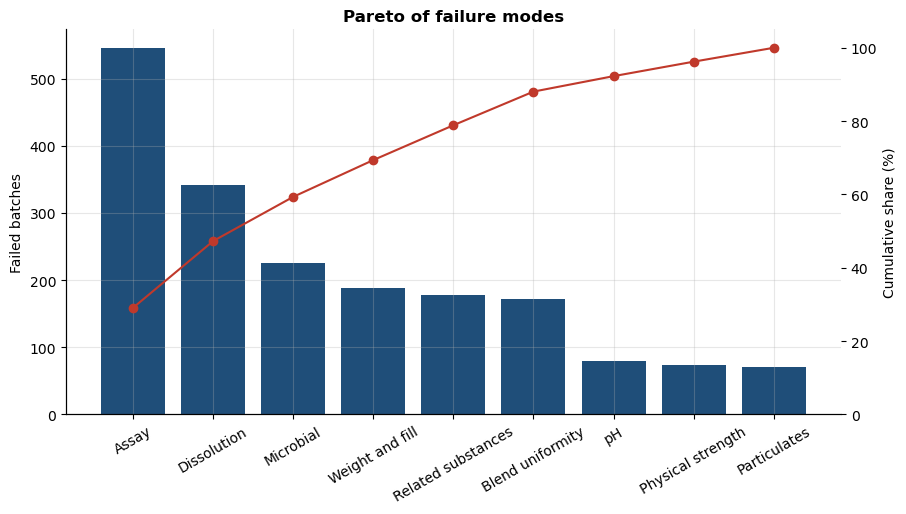

In [370]:
failed = batches[batches[TARGET_COL] == 1]
modes = failed["failure_mode"].value_counts()
pareto = pd.DataFrame({"failures": modes})
pareto["share"] = pareto["failures"] / pareto["failures"].sum()
pareto["cumulative_share"] = pareto["share"].cumsum()
display(pareto.round(4))

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(pareto.index, pareto["failures"], color=PRIMARY)
ax.set_ylabel("Failed batches")
ax.tick_params(axis="x", rotation=30)
ax2 = ax.twinx()
ax2.plot(pareto.index, pareto["cumulative_share"] * 100, color=ALERT, marker="o")
ax2.set_ylabel("Cumulative share (%)")
ax2.set_ylim(0, 105)
ax2.grid(False)
ax.set_title("Pareto of failure modes")
save_figure(fig, "04_failure_pareto")
plt.show()

**Output and chart:** the Pareto bars show failures per mode, and the red line shows the cumulative share. Assay (29.1%) and Dissolution (18.2%) make up 47.3% of failures, and the top six modes reach 88%.

## 4. Trend over time

The failure rate by production year is shown with its interval. The proposal says the
rate has risen since 2019. The chart shows the full history, from 2007.

,batches,failures,failure_rate,ci_low,ci_high
year,,,,,
2007,2033,59,0.0290,0.0226,0.0373
2008,2048,45,0.0220,0.0165,0.0293
2009,2123,43,0.0203,0.0151,0.0272
2010,2279,43,0.0189,0.0140,0.0253
2011,2357,62,0.0263,0.0206,0.0336
2012,2456,69,0.0281,0.0223,0.0354
2013,2567,77,0.0300,0.0241,0.0373
2014,2539,63,0.0248,0.0194,0.0316
2015,3023,99,0.0327,0.0270,0.0397


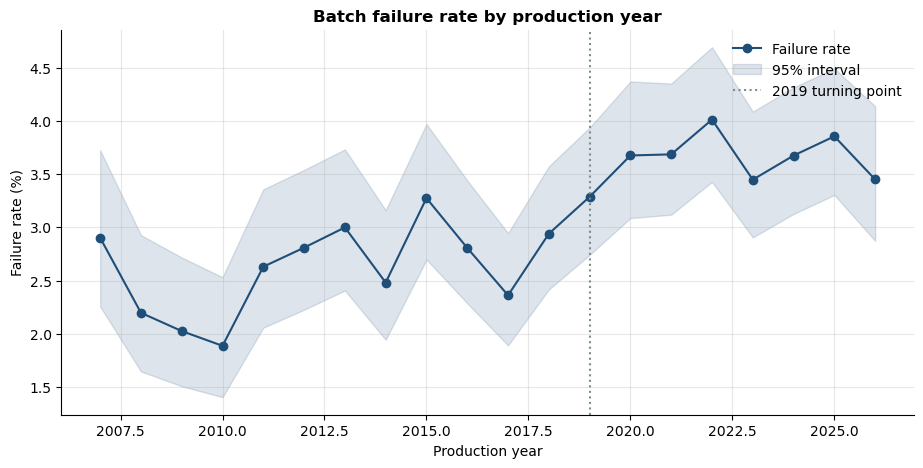

In [373]:
from src.trend import yearly_table

yearly = yearly_table(batches)
display(yearly.round(4).set_index("year"))

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(yearly["year"], yearly["failure_rate"] * 100, color=PRIMARY, marker="o", label="Failure rate")
ax.fill_between(yearly["year"], yearly["ci_low"] * 100, yearly["ci_high"] * 100,
                color=PRIMARY, alpha=0.15, label="95% interval")
ax.axvline(2019, color=NEUTRAL, linestyle=":", label="2019 turning point")
ax.set_xlabel("Production year")
ax.set_ylabel("Failure rate (%)")
ax.set_title("Batch failure rate by production year")
ax.legend()
save_figure(fig, "05_yearly_failure_rate")
plt.show()

**Output and chart:** the line shows the yearly failure rate, with its 95% band in shading. It sits at 1.9–3.0% up to 2014, climbs after the 2019 marker, and peaks at 4.0% in 2022. Since then it has stayed at 3.4–3.9%.

## 5. Sales and inventory context

The sales file covers 2014 to 2025 and contains no batch-level link to production, so it
is summarised separately. It supports the optional demand module (notebook 07).

,orders,units,net_value_kes_m
Sale_Date,,,
2014,7743,112596,433.1
2015,8096,121468,463.3
2016,9102,133750,594.6
2017,9567,134579,623.7
2018,10299,145026,673.5
2019,11136,155797,787.2
2020,12158,171327,937.6
2021,12929,190461,1048.0
2022,13967,202456,1248.8


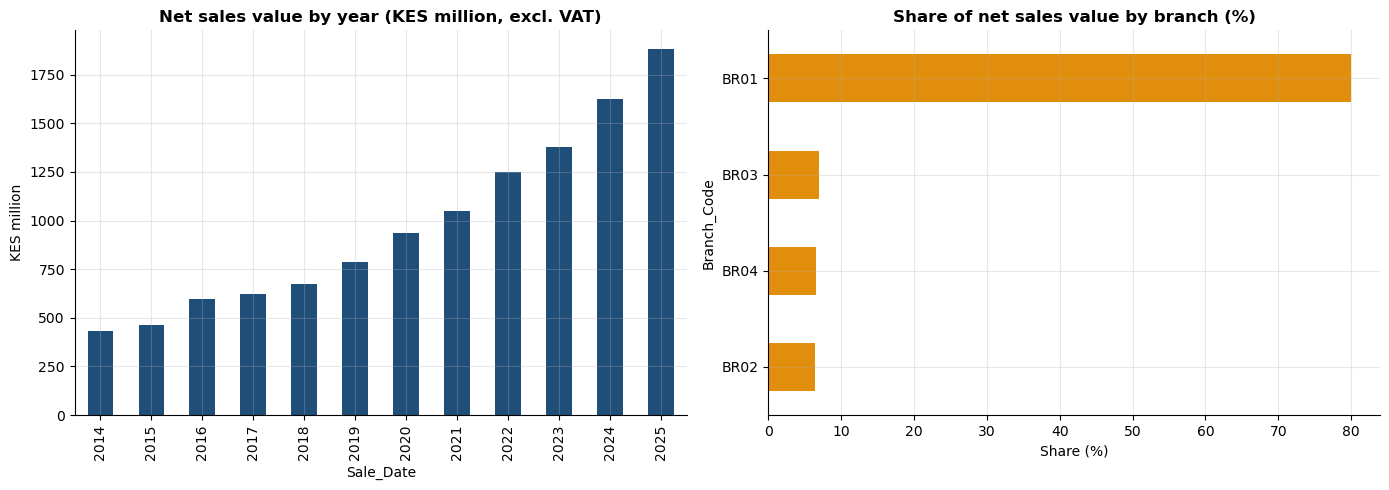

,movements,quantity_change
Movement_Type,,
Goods_Received,12000,4127550
Sale_Out,150000,-2150430


In [376]:
active = sales[sales["is_cancelled"] == 0]
by_year = active.groupby(active["Sale_Date"].dt.year).agg(
    orders=("Sale_ID", "size"),
    units=("Quantity", "sum"),
    net_value_kes_m=("Net_Amount_Excl_VAT_KES", lambda s: s.sum() / 1e6),
)
display(by_year.round(1))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
by_year["net_value_kes_m"].plot.bar(ax=axes[0], color=PRIMARY)
axes[0].set_title("Net sales value by year (KES million, excl. VAT)")
axes[0].set_ylabel("KES million")
share_branch = active.groupby("Branch_Code")["Net_Amount_Excl_VAT_KES"].sum()
(share_branch / share_branch.sum() * 100).sort_values().plot.barh(ax=axes[1], color=ACCENT)
axes[1].set_title("Share of net sales value by branch (%)")
axes[1].set_xlabel("Share (%)")
fig.tight_layout()
save_figure(fig, "06_sales_overview")
plt.show()

movements = inventory.groupby(["Movement_Type"]).agg(movements=("Movement_ID", "size"),
                                                     quantity_change=("Quantity_Change", "sum"))
display(movements)

**Output and charts:** left, net sales grow every year, from KES 433m (2014) to KES 1,884m (2025). Right, branch BR01 earns about 80% of sales value, and the other three branches about 7% each. Inventory shows 4.13m units received against 2.15m sold out.

## 6. Answers to the research questions

The table summarises what the evidence supports. Adjusted answers come from notebooks
03 to 05, and the table will be updated when those are complete.

In [379]:
answers = pd.DataFrame(
    [
        ("Which batches are most likely to fail?",
         "Operator experience, equipment age and raw material quality rank highest, but each is weak alone.",
         "Partly: a weak signal, not a reliable screen (notebook 03)"),
        ("Does maintenance status raise risk after adjustment?",
         "Critical status keeps a clear effect after adjustment; Due Soon does not.",
         "Yes for Critical only (notebook 04)"),
        ("Is the post-2019 rise explained by age, operator or product mix?",
         "Measured factors explain about 60% of the pre-to-post change; the year trend is absorbed after adjustment.",
         "Mostly (notebook 05)"),
        ("Which failure modes dominate?",
         "Assay and dissolution together form roughly 47% of failures.",
         "Yes (this notebook)"),
        ("Do process conditions drift before failures?",
         "Readings stay within limits almost always; prior out-of-control signals only weakly precede failures.",
         "Not materially (notebook 05)"),
        ("Does operator experience matter after controlling for product and equipment?",
         "Yes: the failure rate falls with each experience band.",
         "Yes (notebook 04 and 05)"),
    ],
    columns=["Research question", "Evidence", "Answer"],
)
display(answers.set_index("Research question"))

,Evidence,Answer
Research question,,
Which batches are most likely to fail?,"Operator experience, equipment age and raw material quality rank highest, bu...","Partly: a weak signal, not a reliable screen (notebook 03)"
Does maintenance status raise risk after adjustment?,Critical status keeps a clear effect after adjustment; Due Soon does not.,Yes for Critical only (notebook 04)
"Is the post-2019 rise explained by age, operator or product mix?",Measured factors explain about 60% of the pre-to-post change; the year trend...,Mostly (notebook 05)
Which failure modes dominate?,Assay and dissolution together form roughly 47% of failures.,Yes (this notebook)
Do process conditions drift before failures?,Readings stay within limits almost always; prior out-of-control signals only...,Not materially (notebook 05)
Does operator experience matter after controlling for product and equipment?,Yes: the failure rate falls with each experience band.,Yes (notebook 04 and 05)


**Output:** a summary table of the six research questions with the evidence and answer for each. It is partly yes for prediction (weak signal), yes for Critical maintenance, mostly for the post-2019 rise, and yes for failure modes and operator experience. Drift before failure is not material.

# 7 Yield and assay purity

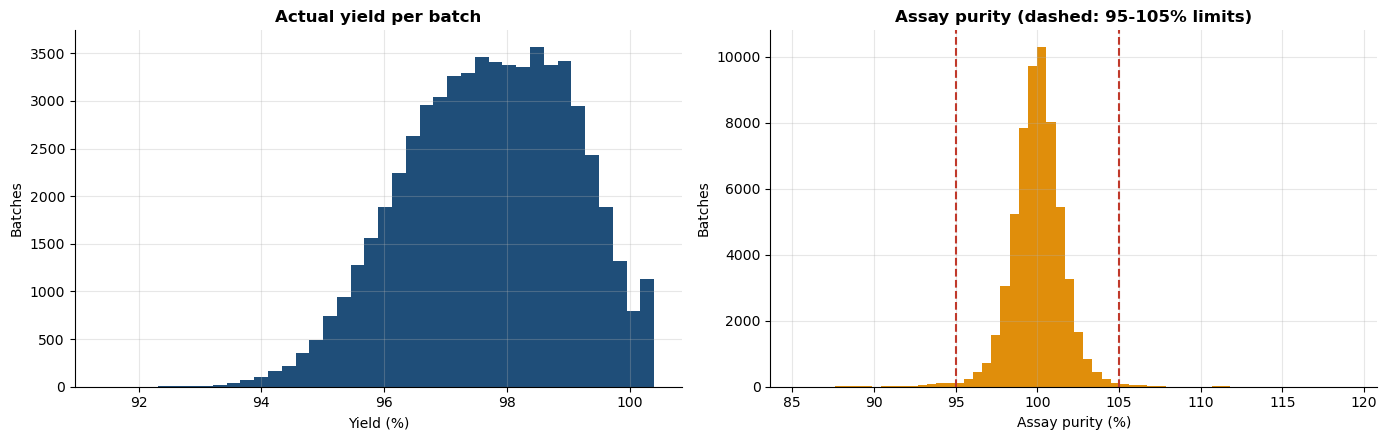

                       count   mean   std    min    25%     50%     75%     max
actual_yield         59770.0  97.71  1.35  91.41  96.75   97.78   98.76  100.40
assay_result_purity  60000.0  99.99  1.65  85.36  99.11  100.02  100.91  119.12


In [382]:
delivered = sales[sales["is_cancelled"] == 0]                               # delivered orders (demand and revenue)
receipts = stock_moves[stock_moves["Quantity_Change"] > 0]                  # goods-received movements (Section 1.9)
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))                             # two charts
ax[0].hist(batches["actual_yield"].dropna(), bins=40, color=PRIMARY)        # yield per batch
ax[0].set(title="Actual yield per batch", xlabel="Yield (%)", ylabel="Batches")
ax[1].hist(batches["assay_result_purity"].dropna(), bins=60, color=ACCENT)  # assay purity per batch
for limit in (95, 105):                                                     # assumed specification limits
    ax[1].axvline(limit, color=ALERT, linestyle="--")
ax[1].set(title="Assay purity (dashed: 95-105% limits)", xlabel="Assay purity (%)", ylabel="Batches")
plt.tight_layout(); plt.show()                                              # display the charts
print(batches[["actual_yield", "assay_result_purity"]].describe().round(2).T)  # numbers behind the charts

**Interpretation**
- **Yield:** a narrow bell centred on **97.8%**. The middle half of batches lies between 96.75% and 98.76%, and the lowest is 91.4%.
- **Assay purity:** centred on **100.0%** (standard deviation 1.65). A thin tail falls outside the assumed 95–105% limits; the lowest is 85.4% and the highest 119.1%.

# 8. Order size and sales value by category

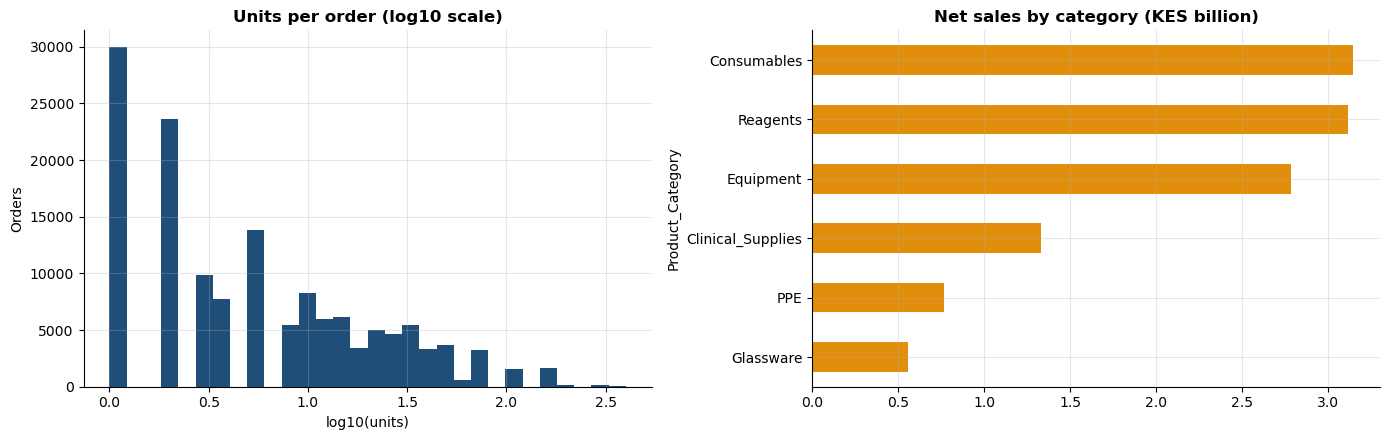

Median units per order: 5.0 | largest order: 400
Share of net sales (%): {'Glassware': 4.8, 'PPE': 6.5, 'Clinical_Supplies': 11.4, 'Equipment': 23.8, 'Reagents': 26.6, 'Consumables': 26.9}


In [385]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))                             # two charts
ax[0].hist(np.log10(delivered["Quantity"]), bins=30, color=PRIMARY)         # units per order on a log scale
ax[0].set(title="Units per order (log10 scale)", xlabel="log10(units)", ylabel="Orders")
value = delivered.groupby("Product_Category")["Net_Amount_Excl_VAT_KES"].sum().sort_values() / 1e9  # KES billion
value.plot.barh(ax=ax[1], color=ACCENT, title="Net sales by category (KES billion)")
plt.tight_layout(); plt.show()                                              # display the charts
print("Median units per order:", delivered["Quantity"].median(), "| largest order:", delivered["Quantity"].max())
print("Share of net sales (%):", (100 * value / value.sum()).round(1).to_dict())

**Interpretation**
- **Order size:** very skewed. The median order is **5 units** and the largest **400**, so medians describe a typical order better than means.
- **Value:** **Consumables (26.9%)** and **Reagents (26.6%)** earn the most, then Equipment (23.8%). Glassware earns only 4.8%, even though every category has about the same number of orders.

# 9. Discount level vs order size

,orders,median_units,mean_units
Discount_Pct,,,
0.0,65862,4.0,7.8
2.5,35480,6.0,18.7
5.0,29866,4.0,14.3
7.5,5716,30.0,44.2
10.0,7031,10.0,30.4


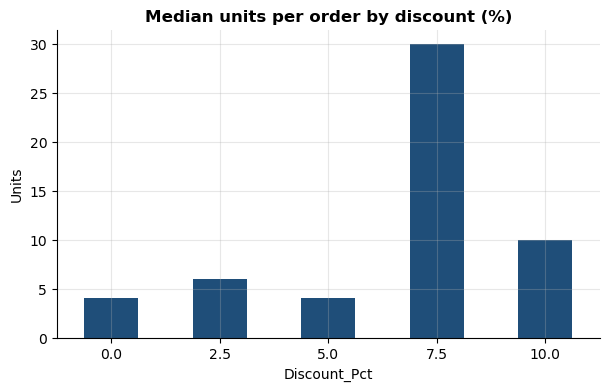

In [388]:
by_discount = delivered.groupby("Discount_Pct")["Quantity"].agg(orders="size", median_units="median", mean_units="mean")
display(by_discount.round(1))                                               # order size per discount level
by_discount["median_units"].plot.bar(figsize=(7, 4), color=PRIMARY, rot=0, title="Median units per order by discount (%)")
plt.ylabel("Units"); plt.show()    

**Interpretation**
- Bigger orders get bigger discounts. The median order is **4 units at 0% discount** and **30 units at 7.5%** (mean 44 units).
- This looks like a **volume-discount policy**, not a revenue leak.

# 10. Failure rate by assay purity band

,batches,failure_rate
assay_result_purity,,
below 95,507,79.1
95-105,59195,2.2
above 105,298,50.3


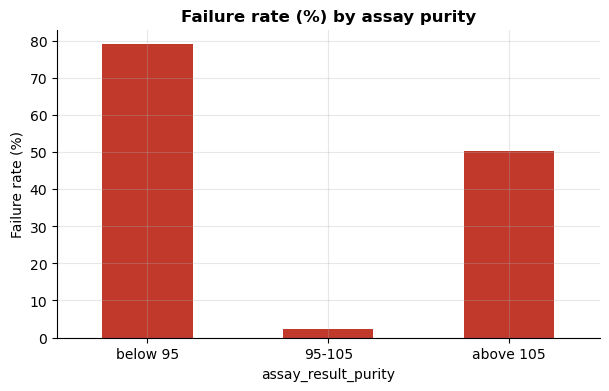

In [391]:
purity_band = pd.cut(batches["assay_result_purity"], [0, 95, 105, 200], labels=["below 95", "95-105", "above 105"])
band_rates = batches.groupby(purity_band, observed=True)[TARGET_COL].agg(batches="size", failure_rate="mean")  # rate per band
display(band_rates.assign(failure_rate=lambda d: (100 * d["failure_rate"]).round(1)))  # in %
(100 * band_rates["failure_rate"]).plot.bar(figsize=(7, 4), color=ALERT, rot=0, title="Failure rate (%) by assay purity")
plt.ylabel("Failure rate (%)"); plt.show()                                  # display the chart

**Interpretation**
- Batches **below 95%** purity fail **79.1%** of the time (507 batches), and batches **above 105%** fail **50.3%** (298 batches). Inside the 95–105% range, only **2.2%** fail.
- Purity is the clearest single warning sign. It is measured at release, though, so it cannot be a predictor. That is why it is excluded from the classifier's features.

# 11. Units received vs units sold, by category

,received,sold,received per unit sold
Clinical_Supplies,679450,406380,1.67
Consumables,719400,415164,1.73
Equipment,668050,29925,22.32
Glassware,708150,398889,1.78
PPE,673850,410399,1.64
Reagents,678650,405484,1.67


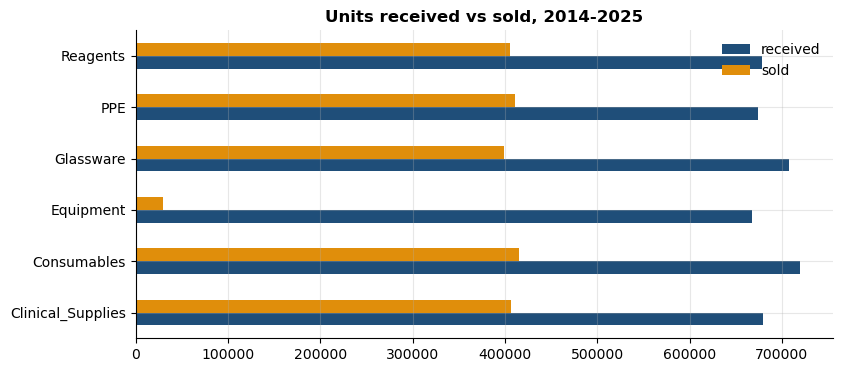

In [394]:
category_of = sales.groupby("Product_ID")["Product_Category"].first()      # product -> category
flow = pd.DataFrame({"received": receipts.groupby(receipts["Product_ID"].map(category_of))["Quantity_Change"].sum(),
                     "sold": delivered.groupby("Product_Category")["Quantity"].sum()})
flow["received per unit sold"] = flow["received"] / flow["sold"]            # buying relative to demand
display(flow.round(2))                                                      # numbers behind the chart
flow[["received", "sold"]].plot.barh(figsize=(9, 4), color=[PRIMARY, ACCENT], title="Units received vs sold, 2014-2025")
plt.show() 

**Interpretation**
- Five categories receive about **1.6–1.8 units for every unit sold**.
- **Equipment received 668,050 units but sold only 29,925, which is 22 times more.** Purchasing is not linked to demand, and Equipment drives the overstock. Confirm the Equipment receipt records with the stores team.

# 12. Correlation of production variables

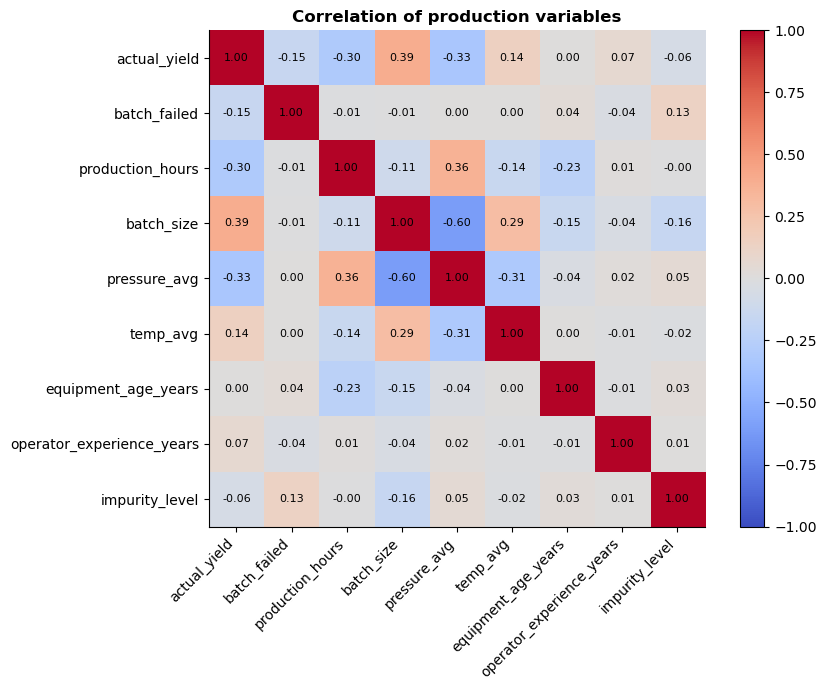

In [397]:
prod_cols = ["actual_yield", "batch_failed", "production_hours", "batch_size", "pressure_avg", "temp_avg",
             "equipment_age_years", "operator_experience_years", "impurity_level"]
corr = batches[prod_cols].corr()                                            # Pearson correlation
fig, ax = plt.subplots(figsize=(9, 7))                                      # new chart
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)                      # red = positive, blue = negative
ax.set_xticks(range(len(prod_cols)), prod_cols, rotation=45, ha="right"); ax.set_yticks(range(len(prod_cols)), prod_cols)
for i in range(len(prod_cols)):                                             # write each value in its cell
    for j in range(len(prod_cols)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
ax.set_title("Correlation of production variables"); ax.grid(False); plt.colorbar(im)
plt.tight_layout(); plt.show()                                              # display the chart

**Interpretation**
- **Yield** rises with batch size (**+0.39**) and falls with pressure (**−0.33**) and production hours (**−0.30**). These links mostly reflect the product mix: liquids are bigger, faster and higher-yield.
- **Failure (`batch_failed`)** is almost unrelated to the pre-release variables: equipment age +0.04, operator experience −0.04, every other variable about 0. Only results measured at release show a link (impurity +0.13, yield −0.15). This agrees with notebook 03's weak classifier.

# STAGE 3 — FEATURE ENGINEERING

# 03 Batch quality classifier (Module A)

**Purpose.** Predict, before release, which batches will fail, and explain the drivers
behind each prediction. This notebook covers the classifier design, the time-separated
validation, model comparison, threshold choice, the test-period result, and the
failure-mode model that proposes a likely cause for each alert.

**Design rules applied.**
1. Only information available before release is used. Assay, dissolution, impurity,
   actual yield and rejection reason are measured at or after release, so they are excluded.
2. Splits follow time: train on 2007 to 2021, validate on 2022 to 2023, test on 2024 to 2026.
3. Imputation medians are fitted on the training period only.
4. The logistic baseline must be beaten by a challenger by a margin before a complex model is adopted.
5. Each model keeps its own decision threshold, chosen on validation, never on test.

In [400]:
# Setup: make the project package importable and apply the shared plot style.
import sys
import warnings
from pathlib import Path

import os


def _find_project_root() -> Path:
    """Locate the project folder (the one containing src/config.py).

    Checks the BQ_PROJECT_ROOT environment variable first, then the current folder
    and each of its parents, so the notebook runs from any working directory.
    """
    env_root = os.environ.get("BQ_PROJECT_ROOT")
    if env_root:
        return Path(env_root).resolve()
    here = Path.cwd().resolve()
    for candidate in [here, *here.parents]:
        if (candidate / "src" / "config.py").exists():
            return candidate
    raise FileNotFoundError(
        "Could not find the project folder (the one containing src/config.py). "
        "Open the notebook from inside the project, or set BQ_PROJECT_ROOT to its path."
    )


ROOT = _find_project_root()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from src.config import TARGET_COL, MIN_RECALL, MIN_PRECISION, ROC_AUC_TARGET
from src.data_io import load_processed
from src.plotting import set_plot_style, save_figure, PRIMARY, ALERT, ACCENT, POSITIVE, NEUTRAL

warnings.filterwarnings("ignore")
set_plot_style()
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 220)
pd.set_option("display.max_colwidth", 80)
print("Project root:", ROOT)

Project root: /Users/apple/Desktop/Capstone-Project


In [401]:
# Load the cleaned tables written by the cleaning step (notebook 01 or the pipeline).
batches = load_processed("batches")
sales = load_processed("sales")
inventory = load_processed("inventory")
print(f"Batches: {len(batches):,} | Sales lines: {len(sales):,} | Inventory movements: {len(inventory):,}")

Batches: 60,000 | Sales lines: 150,000 | Inventory movements: 162,000


## 1. Time-separated split and feature set

In [403]:
from src.modeling import split_by_time
from src.features import NUMERIC_FEATURES, feature_columns, FEATURE_LABELS

split = split_by_time(batches)
display(split.describe().round(4).set_index("partition"))

print("Predictors used (pre-release only):")
features_table = pd.DataFrame({"column": feature_columns()})
features_table["label"] = features_table["column"].map(lambda c: FEATURE_LABELS.get(c, c))
display(features_table)

excluded = ["assay_result_purity", "impurity_level", "dissolution_time_min", "actual_yield",
            "rejection_reason", "failure_mode"]
print("Excluded because they are measured at or after release:", ", ".join(excluded))

,period,batches,failed,failure_rate
partition,,,,
Train,2007-2021,41477,1190,0.0287
Validation,2022-2023,7396,276,0.0373
Test,2024-2026,11127,409,0.0368


Predictors used (pre-release only):


,column,label
0,equipment_age_years,Equipment age (years)
1,maintenance_days_ago,Days since maintenance
2,temp_avg,Average temperature
3,temp_variance,Temperature variance
4,pressure_avg,Average pressure
5,pressure_variance,Pressure variance
6,humidity_avg,Average humidity
7,raw_material_quality,Raw material quality
8,operator_experience_years,Operator experience (years)
9,production_hours,Production hours


Excluded because they are measured at or after release: assay_result_purity, impurity_level, dissolution_time_min, actual_yield, rejection_reason, failure_mode


# 2. Production features

In [405]:
poi_features = pd.DataFrame(index=batches.index)                            # new features, one row per batch
poi_features["maintenance_urgency"] = batches["maintenance_status"].map({"Current": 0, "Due Soon": 1, "Critical": 2})
poi_features["equipment_age_group"] = pd.cut(batches["equipment_age_days"], [-1, 365, 1825, np.inf], labels=["New", "Medium Age", "Old"])
train_rows = batches["year"] <= 2021                                        # limits learned on the training years only
for col in ["temp_variance", "pressure_variance"]:                          # unusually unstable runs
    poi_features[f"high_{col}"] = (batches[col] > batches.loc[train_rows, col].quantile(0.95)).astype(int)
poi_features["quarter"] = batches["production_start"].dt.quarter            # calendar features
poi_features["month"] = batches["production_start"].dt.month
for col in ["maintenance_urgency", "equipment_age_group", "high_temp_variance", "high_pressure_variance", "quarter"]:
    rate = batches.groupby(poi_features[col], observed=True)[TARGET_COL].mean() * 100  # failure rate per value
    print(f"Failure rate (%) by {col}: {rate.round(2).to_dict()}")

Failure rate (%) by maintenance_urgency: {0: 3.11, 1: 2.93, 2: 6.93}
Failure rate (%) by equipment_age_group: {'New': 2.07, 'Medium Age': 2.62, 'Old': 3.29}
Failure rate (%) by high_temp_variance: {0: 3.05, 1: 4.43}
Failure rate (%) by high_pressure_variance: {0: 3.13, 1: 3.09}
Failure rate (%) by quarter: {1: 3.12, 2: 3.15, 3: 3.19, 4: 3.03}


**Explanation**
- **Maintenance urgency** (0 Current, 1 Due Soon, 2 Critical): failure rates are **3.11%, 2.93% and 6.93%**. The jump comes only at Critical.
- **Equipment age group:** failure rises from **2.07%** (New, up to 1 year) to 2.62% (Medium, 1–5 years) and **3.29%** (Old, over 5 years).
- **High temperature variance** (above the 95th percentile of the training years): **4.43%** against 3.05%. This is a useful process flag.
- **High pressure variance:** no difference (3.09% against 3.13%).
- **Quarter:** no seasonality in quality (3.03–3.19%).
- **Suggestion:** urgency, age group and the temperature-variance flag are good candidates to add to `src/features.py`. Pressure variance and quarter add nothing.

# 3. Weekly demand table (product × week)

In [408]:
week = lambda d: d.dt.to_period("W-SUN").dt.start_time                      # week starting Monday
delivered = sales[sales["is_cancelled"] == 0]                               # delivered orders (demand)
products = sorted(delivered["Product_ID"].unique())                         # every product that has sold
weekly_units = delivered.groupby(["Product_ID", week(delivered["Sale_Date"])])["Quantity"].sum().rename("units")
all_weeks = pd.date_range(weekly_units.index.get_level_values(1).min(), weekly_units.index.get_level_values(1).max(), freq="7D")
demand_panel = (weekly_units.reindex(pd.MultiIndex.from_product([products, all_weeks], names=["Product_ID", "week"]), fill_value=0)
                .reset_index())                                             # every product in every week (no sale = 0)
g = demand_panel.groupby("Product_ID")["units"]                             # per-product series
for lag in (1, 2, 4, 52):                                                   # demand 1, 2, 4 and 52 weeks earlier
    demand_panel[f"lag{lag}"] = g.shift(lag)
demand_panel["roll12"] = g.transform(lambda s: s.shift(1).rolling(12).mean())  # average of the previous 12 weeks
demand_panel["std12"] = g.transform(lambda s: s.shift(1).rolling(12).std())  # variability of the previous 12 weeks
demand_panel["week_of_year"] = demand_panel["week"].dt.isocalendar().week.astype(int)  # calendar feature


def croston_sba(units, alpha=0.1):                                          # Croston-SBA forecast for intermittent demand
    size = gap = None                                                       # smoothed order size and gap between orders
    since, out = 1, []                                                      # weeks since the last sale; forecasts
    for u in units:
        out.append(np.nan if size is None else (1 - alpha / 2) * size / gap)  # forecast made before seeing this week
        if u > 0:                                                           # a sale: update size and gap
            size, gap = (u, since) if size is None else (size + alpha * (u - size), gap + alpha * (since - gap))
            since = 1
        else:
            since += 1                                                      # no sale: the gap grows
    return out


demand_panel["sba"] = g.transform(lambda s: pd.Series(croston_sba(s.to_numpy()), index=s.index))  # past weeks only
print("demand_panel:", demand_panel.shape, f"| zero-demand weeks: {(demand_panel['units'] == 0).mean():.1%}")

demand_panel: (188100, 11) | zero-demand weeks: 47.6%


**Explanation**
- **188,100 rows** (300 products × 627 weeks). **47.6%** of product-weeks have no sales, which confirms intermittent demand.
- **Features:**
  - demand 1, 2, 4 and 52 weeks earlier;
  - the 12-week average and spread;
  - week of the year;
  - the **Croston-SBA** forecast.
- Every feature uses past weeks only, so nothing from the future leaks in.

# 4. Weekly stock table (branch × product × week) and the 14-day stock-out target

In [411]:
wm = (stock_moves.assign(week=week(stock_moves["Movement_Date"]), sold=(-stock_moves["Quantity_Change"]).clip(lower=0),
                         received=stock_moves["Quantity_Change"].clip(lower=0))
      .groupby(["Branch_Code", "Product_ID", "week"])[["sold", "received"]].sum())  # weekly units out and in
pairs = wm.index.droplevel("week").unique()                                 # branch-product pairs that trade
full = pd.MultiIndex.from_tuples([(b, p, w) for b, p in pairs for w in all_weeks], names=wm.index.names)
stock_panel = wm.reindex(full, fill_value=0).reset_index()                  # every pair in every week
gs = stock_panel.groupby(["Branch_Code", "Product_ID"])                     # per-pair series
stock_panel["stock"] = (stock_panel["received"] - stock_panel["sold"]).groupby([stock_panel["Branch_Code"], stock_panel["Product_ID"]]).cumsum()
stock_panel["roll4"] = gs["sold"].transform(lambda s: s.rolling(4, min_periods=1).mean())  # recent weekly demand
stock_panel["roll12"] = gs["sold"].transform(lambda s: s.rolling(12, min_periods=1).mean())
stock_panel["rec4"] = gs["received"].transform(lambda s: s.rolling(4, min_periods=1).sum())  # units received in 4 weeks
stock_panel["cover_weeks"] = stock_panel["stock"] / (stock_panel["roll12"] + 1)  # weeks the stock would last
nxt1, nxt2 = gs["stock"].shift(-1), gs["stock"].shift(-2)                   # stock at the end of the next two weeks
stock_panel["stockout_2w"] = ((nxt1 <= 0) | (nxt2 <= 0)).astype(float).where(nxt2.notna())  # target: out of stock within 14 days
stock_panel["category"] = stock_panel["Product_ID"].map(category_of)
print("stock_panel:", stock_panel.shape, f"| weeks ending out of stock: {(stock_panel['stock'] <= 0).mean():.1%}")

stock_panel: (752400, 12) | weeks ending out of stock: 22.9%


**Explanation**
- **752,400 rows** (1,200 branch–product pairs × 627 weeks), with weekly units sold and received, stock at week end, recent demand, recent receipts and weeks of cover.
- **22.9%** of weeks end with no stock.
- **Target `stockout_2w`:** 1 if the item runs out within the next two weeks. It is only defined where two future weeks exist.

# STAGE 4 — MODELLING
This section focuses on batch classifier, equipment reliability, process control and trend, the risk score and back-test, and the demand forecast. 

## 1. Fit and compare the models

Three models are trained on the training period: a logistic regression baseline, a random
forest, and gradient boosting (XGBoost). All use class weighting, because only about three
percent of batches fail. The fitting function returns every artefact used below.

In [415]:
from src.modeling import fit_classifier_suite

suite = fit_classifier_suite(batches)
cols = ["roc_auc", "pr_auc", "precision", "recall", "f1", "flag_rate",
        "true_positives", "false_positives", "false_negatives"]

print("VALIDATION (2022-2023): used to compare models and set thresholds")
display(suite["validation_table"][cols].round(4))
print("TEST (2024-2026): reported once, after all choices were made")
display(suite["test_table"][cols].round(4))

thr = {k: round(v, 4) for k, v in suite["thresholds"].items()}
print("Decision thresholds fixed on validation:", thr)
print("Adopted model:", suite["chosen_model"])

VALIDATION (2022-2023): used to compare models and set thresholds


,roc_auc,pr_auc,precision,recall,f1,flag_rate,true_positives,false_positives,false_negatives
model,,,,,,,,,
Logistic regression (baseline),0.5939,0.0534,0.0428,0.8080,0.0813,0.7043,223,4986,53
Random forest,0.5495,0.0432,0.0405,0.8225,0.0772,0.7574,227,5375,49
Gradient boosting (scikit-learn),0.5392,0.0418,0.0406,0.8007,0.0772,0.7365,221,5226,55


TEST (2024-2026): reported once, after all choices were made


,roc_auc,pr_auc,precision,recall,f1,flag_rate,true_positives,false_positives,false_negatives
model,,,,,,,,,
Logistic regression (baseline),0.5812,0.0564,0.0399,0.8191,0.0761,0.7547,335,8063,74
Random forest,0.5635,0.0454,0.0385,0.8753,0.0738,0.8351,358,8934,51
Gradient boosting (scikit-learn),0.5539,0.0474,0.0378,0.8533,0.0724,0.8301,349,8887,60


Decision thresholds fixed on validation: {'Logistic regression (baseline)': 0.4952, 'Random forest': 0.4114, 'Gradient boosting (scikit-learn)': 0.4757}
Adopted model: Logistic regression (baseline)


### Reading the comparison

The question is whether any model separates failing from passing batches well. Threshold
metrics (precision, recall) depend on the threshold chosen, but ROC-AUC and PR-AUC do not.
ROC-AUC of 0.5 means no separation, and the proposal target is 0.80. The boosted models do
not beat the logistic baseline on validation, so the adoption rule keeps the baseline.

## 2. Ranking curves on the test period

The ROC curve shows how well each model ranks failing batches above passing ones. The
precision-recall curve is more informative when failures are rare, as they are here, because
its baseline is the failure rate itself.

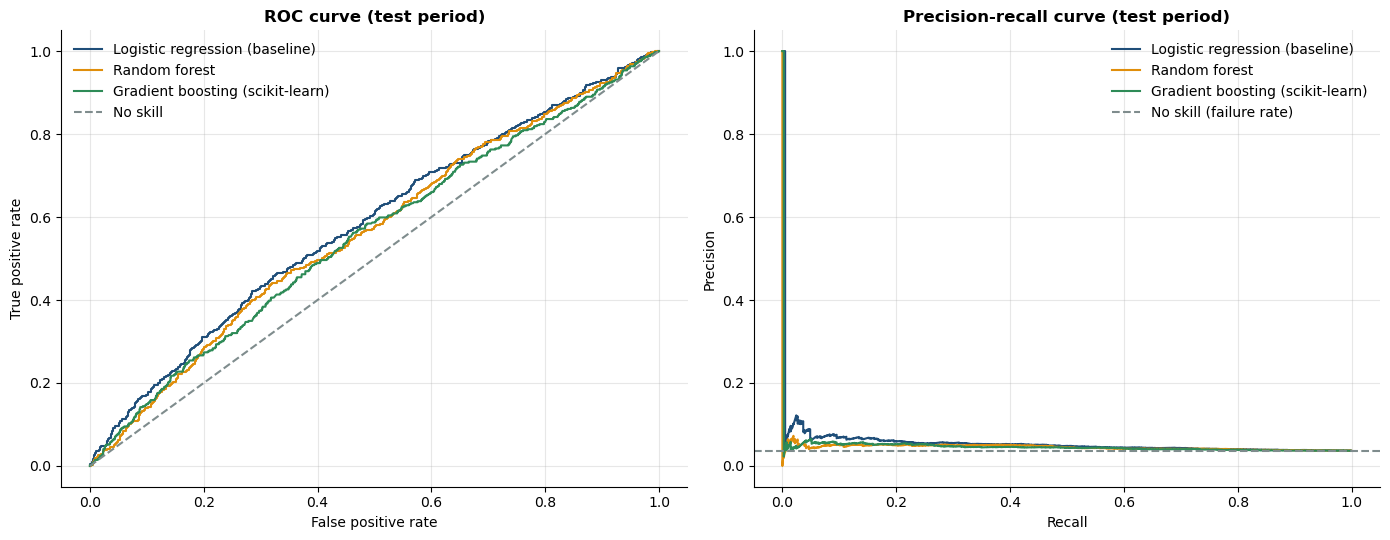

In [418]:
from sklearn.metrics import roc_curve, precision_recall_curve

y_test = suite["y_test"]
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
colours = [PRIMARY, ACCENT, POSITIVE]
for colour, (name, proba) in zip(colours, suite["test_proba"].items()):
    fpr, tpr, _ = roc_curve(y_test, proba)
    axes[0].plot(fpr, tpr, color=colour, label=name)
    prec, rec, _ = precision_recall_curve(y_test, proba)
    axes[1].plot(rec, prec, color=colour, label=name)
axes[0].plot([0, 1], [0, 1], color=NEUTRAL, linestyle="--", label="No skill")
axes[0].set(title="ROC curve (test period)", xlabel="False positive rate", ylabel="True positive rate")
axes[1].axhline(y_test.mean(), color=NEUTRAL, linestyle="--", label="No skill (failure rate)")
axes[1].set(title="Precision-recall curve (test period)", xlabel="Recall", ylabel="Precision")
axes[0].legend()
axes[1].legend()
fig.tight_layout()
save_figure(fig, "07_roc_pr_curves")
plt.show()

**Charts:** left, the ROC curves of all three models sit only slightly above the diagonal (test ROC-AUC 0.55–0.58). Right, the precision–recall curves stay near the 3.7% no-skill line. The ranking is weak.

## 3. Confusion matrix at the adopted threshold

The matrix shows the actual outcome against the alert decision. With a low failure rate, a
high recall target forces the alert to cover most of the batches, so the false-alarm count is
large. That trade-off is the central business decision for QA.

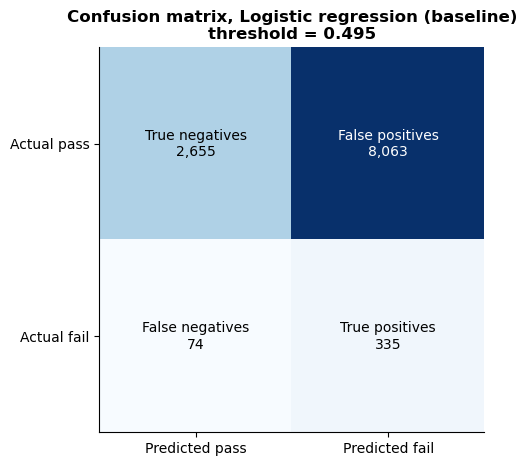

Flagged share: 75.5% of test batches


In [421]:
from sklearn.metrics import confusion_matrix

chosen = suite["chosen_model"]
proba = suite["test_proba"][chosen]
thr = suite["thresholds"][chosen]
pred = (proba >= thr).astype(int)
cm = confusion_matrix(y_test, pred, labels=[0, 1])

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(cm, cmap="Blues")
labels = [["True negatives", "False positives"], ["False negatives", "True positives"]]
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{labels[i][j]}\n{cm[i, j]:,}", ha="center", va="center",
                color="white" if cm[i, j] > cm.max() / 2 else "black")
ax.set_xticks([0, 1], ["Predicted pass", "Predicted fail"])
ax.set_yticks([0, 1], ["Actual pass", "Actual fail"])
ax.set_title(f"Confusion matrix, {chosen}\nthreshold = {thr:.3f}")
ax.grid(False)
save_figure(fig, "08_confusion_matrix")
plt.show()
print(f"Flagged share: {pred.mean():.1%} of test batches")

**Chart:** the confusion matrix at threshold 0.495. Of 409 test failures, 335 are caught and 74 missed, but 8,063 good batches are also flagged. In total, 75.5% of batches are flagged.

## 4. Gains: how concentrated is the risk?

If QA reviewed only the highest-risk batches, how many failures would they reach? The gains
table ranks test batches by predicted probability and cuts them into deciles.

,batches,failures,failure_rate,cumulative_failures_share,lift
decile,,,,,
1,1113,69,0.0620,0.1687,1.6866
2,1113,54,0.0485,0.3007,1.3199
3,1112,51,0.0459,0.4254,1.2477
4,1113,36,0.0323,0.5134,0.8800
5,1113,36,0.0323,0.6015,0.8800
6,1112,43,0.0387,0.7066,1.0520
7,1113,28,0.0252,0.7751,0.6844
8,1112,31,0.0279,0.8509,0.7584
9,1113,32,0.0288,0.9291,0.7822


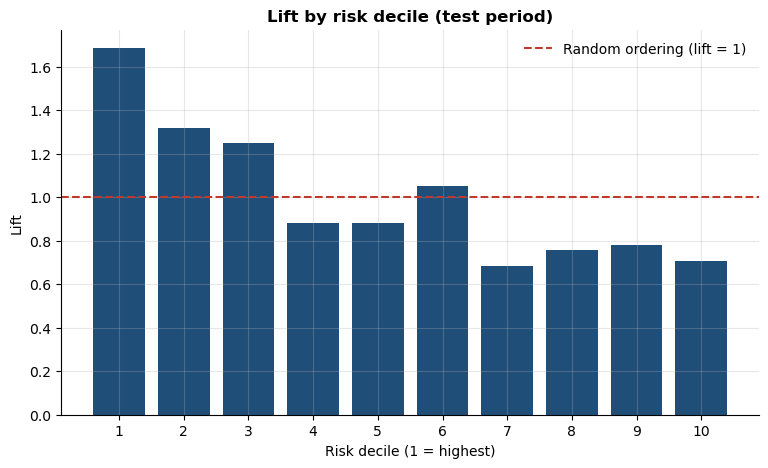

In [424]:
gains = pd.DataFrame({"y": y_test, "p": proba})
gains["decile"] = pd.qcut(gains["p"].rank(method="first", ascending=False), 10, labels=range(1, 11))
table = gains.groupby("decile", observed=True).agg(batches=("y", "size"), failures=("y", "sum"),
                                                    failure_rate=("y", "mean"))
table["cumulative_failures_share"] = table["failures"].cumsum() / table["failures"].sum()
table["lift"] = table["failure_rate"] / y_test.mean()
display(table.round(4))

fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(table.index.astype(str), table["lift"], color=PRIMARY)
ax.axhline(1, color=ALERT, linestyle="--", label="Random ordering (lift = 1)")
ax.set(title="Lift by risk decile (test period)", xlabel="Risk decile (1 = highest)", ylabel="Lift")
ax.legend()
save_figure(fig, "09_lift_by_decile")
plt.show()

**Output and chart:** the bars show lift per risk decile. The top 10% of batches fail at 6.2% (lift 1.69) and hold 16.9% of failures; the top three deciles hold 42.5%. From decile 4 on, lift is about 1 or below (0.68–1.05), so only the first two or three deciles add value.

## 5. What the model uses: permutation importance

Permutation importance measures how much the test-period ROC-AUC falls when one feature is
shuffled. It is a model-agnostic check on which inputs carry the signal. The bars show the
mean drop over five shuffles, and the thin lines show one standard deviation.

,feature,importance_mean,importance_std
label,,,
Operator experience (years),operator_experience_years,0.03622,0.00256
Equipment age (years),equipment_age_years,0.01594,0.00513
Raw material quality,raw_material_quality,0.01405,0.00426
Temperature variance,temp_variance,0.00817,0.00220
Dosage: Syrup,dosage_Syrup,0.00369,0.00176
Dosage: Bolus,dosage_Bolus,0.00277,0.00288
Maintenance: Critical,maintenance_critical,0.00266,0.00088
Dosage: Oral Liquid,dosage_Oral Liquid,0.00217,0.00203
Maintenance: Due Soon,maintenance_due_soon,0.00189,0.00100


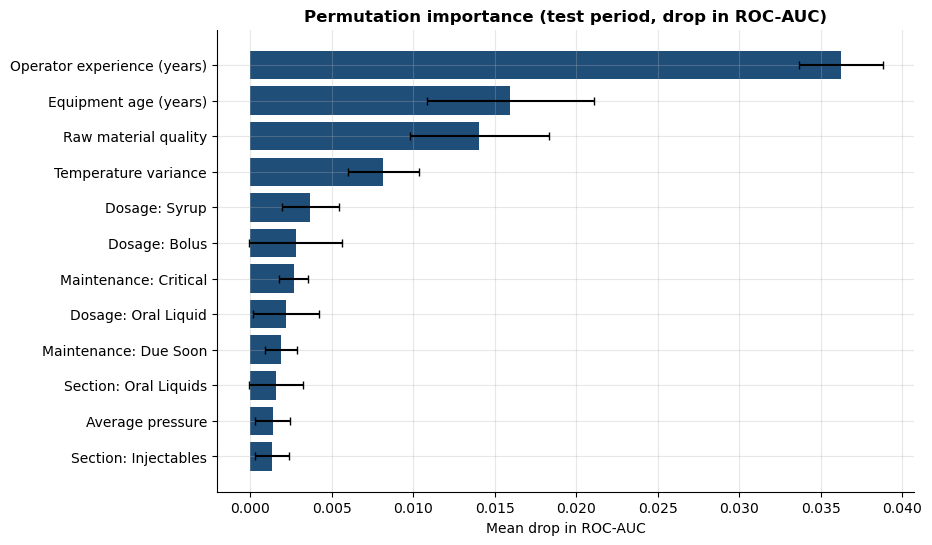

In [427]:
imp = suite["importance"].head(12).iloc[::-1]
display(suite["importance"].head(12).round(5).set_index("label"))

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(imp["label"], imp["importance_mean"], xerr=imp["importance_std"], color=PRIMARY, capsize=3)
ax.set(title="Permutation importance (test period, drop in ROC-AUC)", xlabel="Mean drop in ROC-AUC")
save_figure(fig, "10_feature_importance")
plt.show()

**Output and chart:** the bars show how much ROC-AUC falls when each input is shuffled. Operator experience (0.036) leads, followed by equipment age (0.016) and raw material quality (0.014). Maintenance: Critical is small (0.003) because few batches have it.

## 6. Explaining individual alerts

For each batch, the model reports the three features that push its risk up the most, and a
recommended action tied to the leading driver. The chart uses the adopted model's own
contributions, so the explanation matches the prediction exactly.

In [430]:
from src.modeling import driver_contributions, top_drivers, recommended_action

contribs = driver_contributions(suite["models"][chosen], suite["X_test"])
drivers = top_drivers(contribs, n=3)
top_risk = pd.Series(proba, index=suite["X_test"].index).nlargest(5).index

example = batches.loc[top_risk, ["batch_id", "production_start", "drug_name", "equipment_id",
                                 "maintenance_status", "batch_passed"]].copy()
example["probability"] = proba[suite["X_test"].index.get_indexer(top_risk)]
example = example.join(drivers[["driver_1", "driver_2", "driver_3"]])
example["recommended_action"] = [recommended_action(f) for f in drivers.loc[top_risk, "driver_1_feature"]]
display(example.round(4).set_index("batch_id"))

,production_start,drug_name,equipment_id,maintenance_status,batch_passed,probability,driver_1,driver_2,driver_3,recommended_action
batch_id,,,,,,,,,,
SUS-24-0008,2024-02-19,Sucra Suspension,LAL/LIQ/003,Critical,0,0.8985,Maintenance: Critical,Equipment age (years),Temperature variance,Complete overdue maintenance on this equipment and confirm calibration befor...
AB3-24-0035,2024-10-08,Altoa 300mg Bolus,LAL/TAB/006,Current,0,0.8907,Temperature variance,Equipment age (years),Dosage: Bolus,Review the process trend for this run and verify environmental controls befo...
ACP-26-0009,2026-01-20,Acepril,LAL/TAB/006,Current,1,0.8774,Temperature variance,Equipment age (years),Operator experience (years),Review the process trend for this run and verify environmental controls befo...
HMG-24-0063,2024-04-23,Homagon,LAL/TAB/010,Current,1,0.8747,Temperature variance,Equipment age (years),Operator experience (years),Review the process trend for this run and verify environmental controls befo...
ALT-24-0106,2024-10-14,Altoa Tablets,LAL/TAB/006,Current,1,0.8638,Temperature variance,Equipment age (years),Operator experience (years),Review the process trend for this run and verify environmental controls befo...


**Output:** the five highest-risk test batches, with their top three drivers and a recommended action. The top one, SUS-24-0008 (probability 0.90), is driven by Critical maintenance. The others are led by temperature variance and equipment age.

## 7. Failure-mode model

For each alert, the proposal asks for the likely failure mode. A random forest is trained on
failed batches only. The result is compared with the simplest possible guess (always predict
the most common mode), because a model that does not beat that guess adds no value.

In [433]:
from src.modeling import train_failure_type_model
from sklearn.metrics import accuracy_score, f1_score

train_fail = split.train[split.train[TARGET_COL] == 1]
test_fail = split.test[split.test[TARGET_COL] == 1]
X_tf_train = suite["X_train"].loc[train_fail.index]
X_tf_test = suite["X_test"].loc[test_fail.index]
ft_model = train_failure_type_model(X_tf_train, train_fail["failure_mode"])
pred_mode = ft_model.predict(X_tf_test)
actual_mode = test_fail["failure_mode"].to_numpy()
majority = train_fail["failure_mode"].value_counts().idxmax()

result = pd.DataFrame(
    {
        "accuracy": [accuracy_score(actual_mode, [majority] * len(actual_mode)), accuracy_score(actual_mode, pred_mode)],
        "macro_F1": [f1_score(actual_mode, [majority] * len(actual_mode), average="macro", zero_division=0),
                     f1_score(actual_mode, pred_mode, average="macro", zero_division=0)],
    },
    index=["Majority-class baseline", "Random forest"],
)
display(result.round(4))
print(f"Majority class in training: {majority}")
print("Interpretation: the failure-mode model does not beat the majority baseline on accuracy. "
      "Its macro F1 is higher, so it finds some rarer modes, but the signal is weak.")

,accuracy,macro_F1
Majority-class baseline,0.2861,0.0494
Random forest,0.2200,0.1407


Majority class in training: Assay
Interpretation: the failure-mode model does not beat the majority baseline on accuracy. Its macro F1 is higher, so it finds some rarer modes, but the signal is weak.


**Output:** the failure-mode model has 22.0% accuracy, against 28.6% for always guessing Assay. Its macro F1 is 0.14 against 0.05, so it spots a few rarer modes, but the signal is weak.

Top inputs for the failure mode: {'Average pressure': 0.105, 'Production hours': 0.101, 'Average humidity': 0.087}


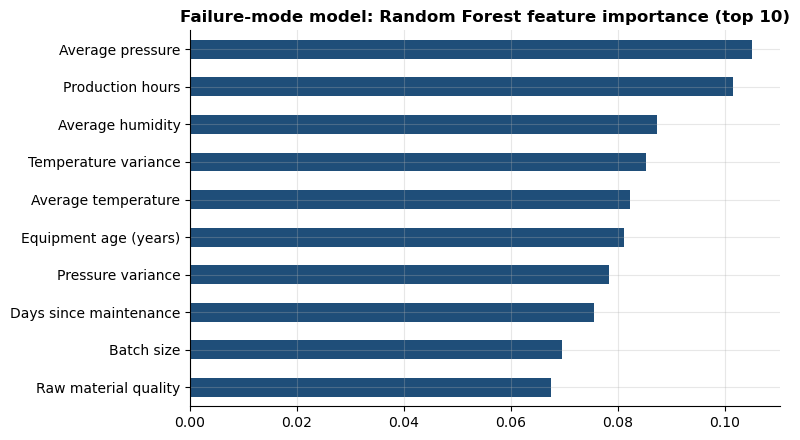

In [435]:
imp_fm = pd.Series(ft_model[-1].feature_importances_, index=X_tf_train.columns).rename(FEATURE_LABELS).sort_values(ascending=False)  # importance per input
print("Top inputs for the failure mode:", imp_fm.head(3).round(3).to_dict())  # three strongest inputs
fig, ax = plt.subplots(figsize=(8, 4.5))                                    # one chart
imp_fm.head(10).iloc[::-1].plot.barh(ax=ax, color=PRIMARY)                  # top 10, largest at the top
ax.set_title("Failure-mode model: Random Forest feature importance (top 10)")
plt.tight_layout(); plt.show()                                              # display the chart

**Output:** the bars show which inputs the failure-mode Random Forest relies on. The top three are average pressure (0.104), production hours (0.102) and average humidity (0.089). The importances are spread evenly, with no input standing out, which matches the weak result above.

**Comparison and choice — failure mode:** Random Forest (accuracy 22.0%, macro F1 0.141) against the majority guess "Assay" (accuracy 28.6%, macro F1 0.049). **No model is adopted for automatic use.** The Random Forest is kept only as a hint of the likely mode, because it beats the baseline on macro F1 but not on accuracy.

## 8. Targets against results

The table compares the proposal's Section 8 targets with what was achieved on the test period.
Targets that are not met are stated plainly rather than adjusted to fit the result.

In [438]:
t = suite["test_table"].loc[chosen]
targets = pd.DataFrame(
    [
        ("Recall at least 0.80 with precision at least 0.19",
         f"Recall {t['recall']:.2f}, precision {t['precision']:.3f} (flags {t['flag_rate']:.0%} of batches)",
         "Not met"),
        ("ROC-AUC at least 0.80", f"{t['roc_auc']:.3f}", "Not met"),
        ("Beats the logistic baseline by a meaningful margin",
         "The adopted model is the logistic baseline; no challenger cleared the margin.", "Not met"),
    ],
    columns=["Proposal target", "Achieved (test period)", "Status"],
)
display(targets.set_index("Proposal target"))
print("Conclusion: pre-release process records do not separate failing from passing batches well enough "
      "for an automated screen. Notebook 06 shows what the composite risk score can and cannot do.")

,Achieved (test period),Status
Proposal target,,
Recall at least 0.80 with precision at least 0.19,"Recall 0.82, precision 0.040 (flags 75% of batches)",Not met
ROC-AUC at least 0.80,0.581,Not met
Beats the logistic baseline by a meaningful margin,The adopted model is the logistic baseline; no challenger cleared the margin.,Not met


Conclusion: pre-release process records do not separate failing from passing batches well enough for an automated screen. Notebook 06 shows what the composite risk score can and cannot do.


**Output:** none of the three Section 8 targets is met. Recall is 0.82 but precision is only 0.040 (target 0.19), and ROC-AUC is 0.581 (target 0.80).

# 04 Equipment reliability and maintenance effect (Module B)

**Purpose.** Quantify how equipment and maintenance status relate to batch failure, test
whether the Critical maintenance signal survives adjustment, rank equipment by failure
risk, and report reliability proxies.

**Important limit.** The data contains no repair times or downtime, so true MTBF and MTTR
cannot be measured. Batch failure is used as a proxy for equipment failure, and every
proxy is labelled as such. Repair times appear only as clearly labelled scenarios.

In [441]:
# Setup: make the project package importable and apply the shared plot style.
import sys
import warnings
from pathlib import Path

import os


def _find_project_root() -> Path:
    """Locate the project folder (the one containing src/config.py).

    Checks the BQ_PROJECT_ROOT environment variable first, then the current folder
    and each of its parents, so the notebook runs from any working directory.
    """
    env_root = os.environ.get("BQ_PROJECT_ROOT")
    if env_root:
        return Path(env_root).resolve()
    here = Path.cwd().resolve()
    for candidate in [here, *here.parents]:
        if (candidate / "src" / "config.py").exists():
            return candidate
    raise FileNotFoundError(
        "Could not find the project folder (the one containing src/config.py). "
        "Open the notebook from inside the project, or set BQ_PROJECT_ROOT to its path."
    )


ROOT = _find_project_root()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from src.config import TARGET_COL, MIN_RECALL, MIN_PRECISION, ROC_AUC_TARGET
from src.data_io import load_processed
from src.plotting import set_plot_style, save_figure, PRIMARY, ALERT, ACCENT, POSITIVE, NEUTRAL

warnings.filterwarnings("ignore")
set_plot_style()
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 220)
pd.set_option("display.max_colwidth", 80)
print("Project root:", ROOT)

Project root: /Users/apple/Desktop/Capstone-Project


In [442]:
# Load the cleaned tables written by the cleaning step (notebook 01 or the pipeline).
batches = load_processed("batches")
sales = load_processed("sales")
inventory = load_processed("inventory")
print(f"Batches: {len(batches):,} | Sales lines: {len(sales):,} | Inventory movements: {len(inventory):,}")

Batches: 60,000 | Sales lines: 150,000 | Inventory movements: 162,000


## 1. Failure rate by maintenance status

,batches,failures,failure_rate,ci_low,ci_high,share_of_batches
maintenance_status,,,,,,
Current,54240,1687,0.0311,0.0297,0.0326,0.9040
Due Soon,5284,155,0.0293,0.0251,0.0342,0.0881
Critical,476,33,0.0693,0.0498,0.0958,0.0079


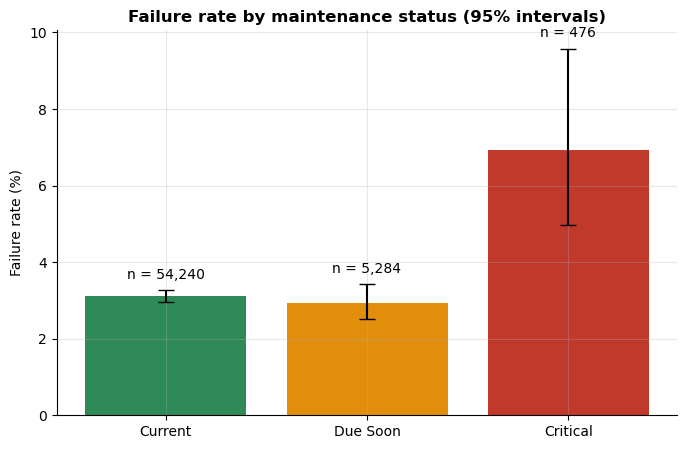

In [444]:
from src.reliability import status_summary

status = status_summary(batches)
display(status.round(4).set_index("maintenance_status"))

fig, ax = plt.subplots(figsize=(8, 5))
err = np.vstack([status["failure_rate"] - status["ci_low"], status["ci_high"] - status["failure_rate"]])
ax.bar(status["maintenance_status"], status["failure_rate"] * 100, yerr=err * 100, capsize=6,
       color=[POSITIVE, ACCENT, ALERT])
for i, row in status.iterrows():
    ax.text(i, row["ci_high"] * 100 + 0.3, f"n = {row['batches']:,}", ha="center")
ax.set(title="Failure rate by maintenance status (95% intervals)", ylabel="Failure rate (%)")
save_figure(fig, "11_status_rates")
plt.show()

**Output and chart:** the bars show the failure rate by maintenance status, with error bars. Critical batches fail at 6.9% (476 batches, 0.8% of all), against 3.1% for Current and 2.9% for Due Soon.

## 2. Does the maintenance signal survive adjustment?

Unadjusted, Critical batches fail more often. The logistic model below adds equipment age,
operator experience, dosage form and section. The reference level is Current. A second
model adds equipment fixed effects, which compares batches within each machine and so
guards against maintenance status merely marking the least reliable machines.

In [447]:
from src.reliability import fit_maintenance_model, odds_ratio_table

adjusted = fit_maintenance_model(batches)
or_main = odds_ratio_table(adjusted)
display(or_main.round(4).set_index("term"))

fixed = fit_maintenance_model(batches, with_equipment_fixed_effects=True)
or_fixed = odds_ratio_table(fixed)
or_fixed = or_fixed[or_fixed["term"].str.contains("Maintenance|age|operator")]
print("Sensitivity: equipment fixed effects (within-machine comparison)")
display(or_fixed.round(4).set_index("term"))

,coefficient,odds_ratio,or_ci_low,or_ci_high,p_value
term,,,,,
Maintenance: Critical,0.8462,2.3308,1.6269,3.3392,0.0000
Maintenance: Due Soon,-0.0573,0.9443,0.7988,1.1163,0.5018
Equipment age (per year),0.0321,1.0326,1.0247,1.0406,0.0000
Operator experience (per year),-0.0356,0.9650,0.9579,0.9723,0.0000


Sensitivity: equipment fixed effects (within-machine comparison)


,coefficient,odds_ratio,or_ci_low,or_ci_high,p_value
term,,,,,
Maintenance: Critical,0.8548,2.3509,1.6397,3.3705,0.0000
Maintenance: Due Soon,-0.0497,0.9515,0.8049,1.1249,0.5606
Equipment age (per year),0.0345,1.0351,1.0261,1.0443,0.0000


**Output:** after adjustment, Critical status still more than doubles the odds of failure (OR 2.33; 2.35 within the same machine, p < 0.001). Due Soon has no effect (OR 0.94, p = 0.50). Each year of equipment age adds 3.3% to the odds, and each year of operator experience cuts them by 3.5%.

### Forest plot of the adjusted odds ratios

An odds ratio above 1 means higher failure odds than the reference. A bar that does not
cross 1 is a statistically clear effect at the 95 percent level.

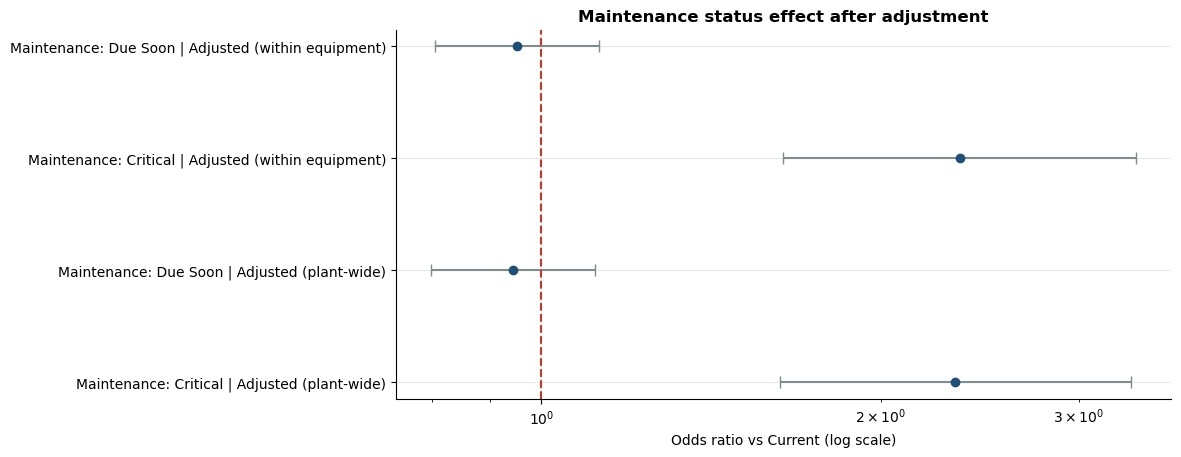

In [450]:
forest = pd.concat([
    or_main.assign(model="Adjusted (plant-wide)"),
    or_fixed.assign(model="Adjusted (within equipment)"),
])
forest = forest[forest["term"].str.contains("Maintenance")]
fig, ax = plt.subplots(figsize=(10, 4.8))
y_positions = np.arange(len(forest))
ax.errorbar(forest["odds_ratio"], y_positions,
            xerr=[forest["odds_ratio"] - forest["or_ci_low"], forest["or_ci_high"] - forest["odds_ratio"]],
            fmt="o", color=PRIMARY, ecolor=NEUTRAL, capsize=4)
ax.axvline(1, color=ALERT, linestyle="--")
ax.set_yticks(y_positions, [f"{t} | {m}" for t, m in zip(forest["term"], forest["model"])])
ax.set_xscale("log")
ax.set_xlabel("Odds ratio vs Current (log scale)")
ax.set_title("Maintenance status effect after adjustment")
save_figure(fig, "12_adjusted_odds_ratio")
plt.show()

**Chart:** a forest plot of the odds ratios with 95% intervals. Critical sits clearly right of the dashed line at 1 in both models, and Due Soon crosses it.

**Model comparison, feature importance and choice — maintenance effect**

| Model | Critical odds ratio (95% CI) | Due Soon odds ratio | Equipment age, per year |
|---|---|---|---|
| **Adjusted logistic model (plant-wide)** | **2.33 (1.63–3.34)** | 0.94 (p = 0.50) | 1.033 |
| Adjusted with equipment fixed effects | 2.35 (1.64–3.37) | 0.95 (p = 0.56) | 1.035 |

- **Chosen: the plant-wide adjusted model.** The within-machine model is used as a check, and it gives almost the same answer.
- **Feature importance (effect size):** Critical status has the largest effect (more than double the odds). Each year of operator experience lowers the odds by 3.5%, and each year of equipment age raises them by 3.3%. Due Soon has no effect.

## 3. Equipment ranking: observed versus expected failures

Machines differ in what they make, so raw failure rates are not a fair ranking. Indirect
standardisation computes the failures each machine would expect given its section and dosage
form, using plant-wide rates. The standardised ratio is observed over expected: a value above
1 means more failures than its product mix predicts. The exact Poisson interval shows whether
that excess is statistically clear.

,equipment_name,manufacturing_section,batches,failures,failure_rate,expected_failures,standardised_ratio,ratio_ci_low,ratio_ci_high,priority
equipment_id,,,,,,,,,,
LAL/TAB/023,Semi-Auto Capsule Filling Machine,Oral Solids,27,1,0.037,0.850,1.176,0.030,6.553,"Watch: above expected, interval includes 1"
LAL/LIQ/003,Liquids Mfg Tank (500 L),Oral Liquids,4097,158,0.039,145.126,1.089,0.926,1.272,"Watch: above expected, interval includes 1"
LAL/TAB/006,35 STN Compression Machine,Oral Solids,13411,472,0.035,435.133,1.085,0.989,1.187,"Watch: above expected, interval includes 1"
LAL/TAB/007,Coating Machine 1,Oral Solids,4784,152,0.032,141.297,1.076,0.912,1.261,"Watch: above expected, interval includes 1"
LAL/TAB/011,Capsule Filling Machine 2,Oral Solids,2932,93,0.032,92.329,1.007,0.813,1.234,"Watch: above expected, interval includes 1"
LAL/CRM/001,Creams Mixing Tank,Creams & Ointments,1480,43,0.029,43.000,1.000,0.724,1.347,Standard
LAL/INJ/003,Ampoule Filling & Sealing Machine,Injectables,1068,51,0.048,51.000,1.000,0.745,1.315,Standard
LAL/TAB/010,Capsule Filling Machine 1,Oral Solids,5107,160,0.031,160.820,0.995,0.847,1.162,Standard
LAL/TAB/028,61 STN B Tablet Compression Machine,Oral Solids,6222,177,0.028,181.732,0.974,0.836,1.128,Standard


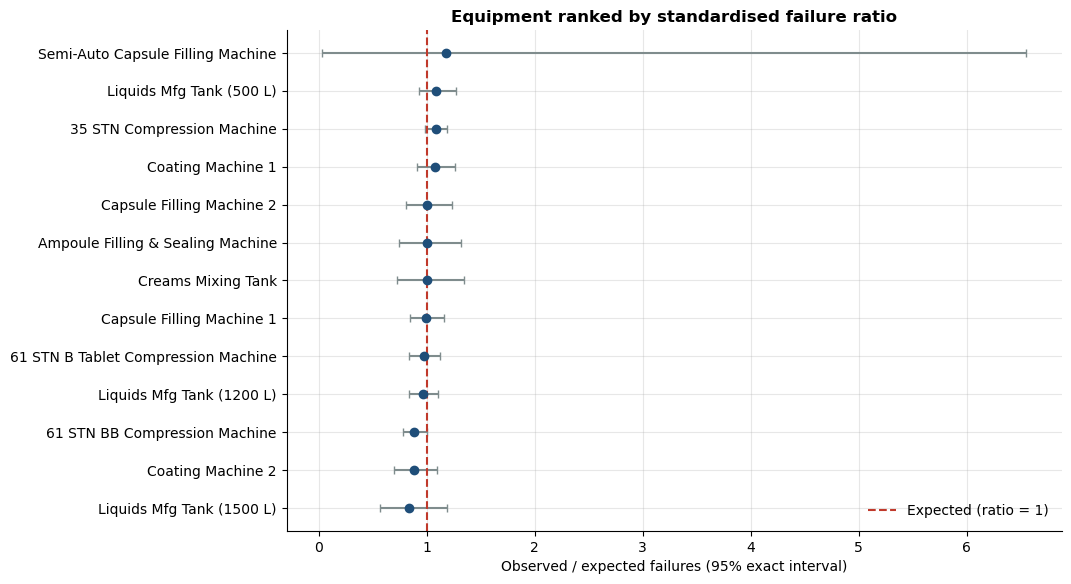

In [454]:
from src.reliability import equipment_table

equipment = equipment_table(batches)
view = equipment[["equipment_id", "equipment_name", "manufacturing_section", "batches", "failures",
                  "failure_rate", "expected_failures", "standardised_ratio", "ratio_ci_low",
                  "ratio_ci_high", "priority"]]
display(view.round(3).set_index("equipment_id"))

ordered = equipment.sort_values("standardised_ratio")
fig, ax = plt.subplots(figsize=(10, 6.5))
y_positions = np.arange(len(ordered))
ax.errorbar(ordered["standardised_ratio"], y_positions,
            xerr=[ordered["standardised_ratio"] - ordered["ratio_ci_low"],
                  ordered["ratio_ci_high"] - ordered["standardised_ratio"]],
            fmt="o", color=PRIMARY, ecolor=NEUTRAL, capsize=3)
ax.axvline(1, color=ALERT, linestyle="--", label="Expected (ratio = 1)")
ax.set_yticks(y_positions, ordered["equipment_name"])
ax.set_xlabel("Observed / expected failures (95% exact interval)")
ax.set_title("Equipment ranked by standardised failure ratio")
ax.legend()
save_figure(fig, "13_equipment_ratio")
plt.show()

**Output:** the dots show each machine's observed/expected failure ratio, with its interval. The top ratio is 1.18 (LAL/TAB/023, only 27 batches). Every interval crosses 1, so no machine is a clear outlier, and five are on Watch.

## 4. Reliability proxies and labelled availability scenarios

The mean time between failures (MTBF) proxy is production hours per batch failure. Availability
needs a repair time, which the data does not contain. The three columns below use repair times of
2, 8 and 24 hours. These are assumptions for comparison only, not measurements.

In [457]:
proxy = equipment[["equipment_id", "equipment_name", "production_hours", "failures",
                   "proxy_mtbf_production_hours", "proxy_batches_between_failures",
                   "scenario_availability_mttr_2h", "scenario_availability_mttr_8h",
                   "scenario_availability_mttr_24h"]]
display(proxy.round(3).set_index("equipment_id"))
print("PROXY LABEL: MTBF here is production hours per batch failure. It is not a measured MTBF.")
print("SCENARIO LABEL: availability columns assume repair times of 2, 8 and 24 hours (assumptions).")

,equipment_name,production_hours,failures,proxy_mtbf_production_hours,proxy_batches_between_failures,scenario_availability_mttr_2h,scenario_availability_mttr_8h,scenario_availability_mttr_24h
equipment_id,,,,,,,,
LAL/TAB/023,Semi-Auto Capsule Filling Machine,218.8,1,218.800,27.000,0.991,0.965,0.901
LAL/LIQ/003,Liquids Mfg Tank (500 L),29476.3,158,186.559,25.930,0.989,0.959,0.886
LAL/TAB/006,35 STN Compression Machine,237588.7,472,503.366,28.413,0.996,0.984,0.954
LAL/TAB/007,Coating Machine 1,118919.0,152,782.362,31.474,0.997,0.990,0.970
LAL/TAB/011,Capsule Filling Machine 2,51048.6,93,548.910,31.527,0.996,0.986,0.958
LAL/CRM/001,Creams Mixing Tank,16534.3,43,384.519,34.419,0.995,0.980,0.941
LAL/INJ/003,Ampoule Filling & Sealing Machine,15269.1,51,299.394,20.941,0.993,0.974,0.926
LAL/TAB/010,Capsule Filling Machine 1,90504.3,160,565.652,31.919,0.996,0.986,0.959
LAL/TAB/028,61 STN B Tablet Compression Machine,192394.3,177,1086.973,35.153,0.998,0.993,0.978


PROXY LABEL: MTBF here is production hours per batch failure. It is not a measured MTBF.
SCENARIO LABEL: availability columns assume repair times of 2, 8 and 24 hours (assumptions).


**Output:** the MTBF proxy runs from about **187 production hours per failure** (LAL/LIQ/003, the 500 L liquids tank) to about **1,113** (LAL/TAB/027, Coating Machine 2). With a 24-hour repair time, availability would range from 0.886 to 0.979. These availability columns are scenarios built on assumed repair times, not measurements.

## 5. Ranked maintenance list

The list ranks equipment by the standardised ratio and attaches a recommended maintenance step
to each priority level. The priority rule is conservative: a machine is treated as a clear
priority only when its excess failures are statistically clear.

In [460]:
action = {
    "High: above expected, interval excludes 1": "Schedule a condition review and root-cause check now.",
    "Watch: above expected, interval includes 1": "Review maintenance records and trend the process readings monthly.",
    "Standard": "Continue planned maintenance.",
}
ranked = equipment[["equipment_id", "equipment_name", "manufacturing_section", "batches", "failures",
                    "standardised_ratio", "priority"]].copy()
ranked.insert(0, "rank", range(1, len(ranked) + 1))
ranked["recommended_maintenance_step"] = ranked["priority"].map(action)
display(ranked.round(3).set_index("rank"))

,equipment_id,equipment_name,manufacturing_section,batches,failures,standardised_ratio,priority,recommended_maintenance_step
rank,,,,,,,,
1,LAL/TAB/023,Semi-Auto Capsule Filling Machine,Oral Solids,27,1,1.176,"Watch: above expected, interval includes 1",Review maintenance records and trend the process readings monthly.
2,LAL/LIQ/003,Liquids Mfg Tank (500 L),Oral Liquids,4097,158,1.089,"Watch: above expected, interval includes 1",Review maintenance records and trend the process readings monthly.
3,LAL/TAB/006,35 STN Compression Machine,Oral Solids,13411,472,1.085,"Watch: above expected, interval includes 1",Review maintenance records and trend the process readings monthly.
4,LAL/TAB/007,Coating Machine 1,Oral Solids,4784,152,1.076,"Watch: above expected, interval includes 1",Review maintenance records and trend the process readings monthly.
5,LAL/TAB/011,Capsule Filling Machine 2,Oral Solids,2932,93,1.007,"Watch: above expected, interval includes 1",Review maintenance records and trend the process readings monthly.
6,LAL/CRM/001,Creams Mixing Tank,Creams & Ointments,1480,43,1.000,Standard,Continue planned maintenance.
7,LAL/INJ/003,Ampoule Filling & Sealing Machine,Injectables,1068,51,1.000,Standard,Continue planned maintenance.
8,LAL/TAB/010,Capsule Filling Machine 1,Oral Solids,5107,160,0.995,Standard,Continue planned maintenance.
9,LAL/TAB/028,61 STN B Tablet Compression Machine,Oral Solids,6222,177,0.974,Standard,Continue planned maintenance.


**Output:** the ranked list of all 13 machines with a maintenance action. Ranks 1–5 are Watch, with LAL/LIQ/003 and LAL/TAB/006 the large-volume machines to review first. The rest are Standard.

# 6. Predicting maintenance status
The sections measure the effect of maintenance status on failure. This model asks whether status (Current, Due Soon, Critical) can be **predicted** from the production record, so overdue equipment can be caught early. Models: baseline (always Current), Logistic Regression, Random Forest; metric macro F1.

In [463]:
from sklearn.pipeline import make_pipeline                                  # chain imputation and model
from sklearn.linear_model import LinearRegression                           # linear regression
from sklearn.metrics import f1_score, recall_score                          # balanced metrics for rare classes
from src.features import build_features                                     # pre-release inputs used by the classifier

Xb = build_features(batches).drop(columns=["maintenance_due_soon", "maintenance_critical", "maintenance_days_ago"])  # no answer leaks in
Xb["year"], Xb["month"] = batches["year"], batches["production_start"].dt.month  # where the batch sits in time
Xb_tr, Xb_te, yb_tr, yb_te = train_test_split(Xb, batches["maintenance_status"], test_size=0.2, stratify=batches["maintenance_status"], random_state=42)
status_models = {"Baseline (always Current)": None,
                 "Logistic Regression": make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=2000)),
                 "Random Forest": make_pipeline(SimpleImputer(strategy="median"), RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight="balanced", n_jobs=-1, random_state=42))}
status_results = {}
for name, model in status_models.items():
    pred = np.full(len(yb_te), "Current") if model is None else model.fit(Xb_tr, yb_tr).predict(Xb_te)  # predicted status
    status_results[name] = {"Macro F1": f1_score(yb_te, pred, average="macro"),
                            "Recall (Critical)": recall_score(yb_te, pred, labels=["Critical"], average="macro", zero_division=0)}
display(pd.DataFrame(status_results).T.round(3))                            # higher is better

,Macro F1,Recall (Critical)
Baseline (always Current),0.317,0.000
Logistic Regression,0.259,0.632
Random Forest,0.501,0.242


**Output:** Random Forest has the best macro F1, **0.501**, against 0.317 for always guessing Current, but it finds only 24.2% of Critical batches. Logistic Regression finds far more Critical batches (63.2%) but mislabels many others (macro F1 0.259). Status can be predicted only moderately well.

Chosen: Random Forest | top inputs: {'month': 0.181, 'equipment_age_years': 0.146, 'year': 0.082}


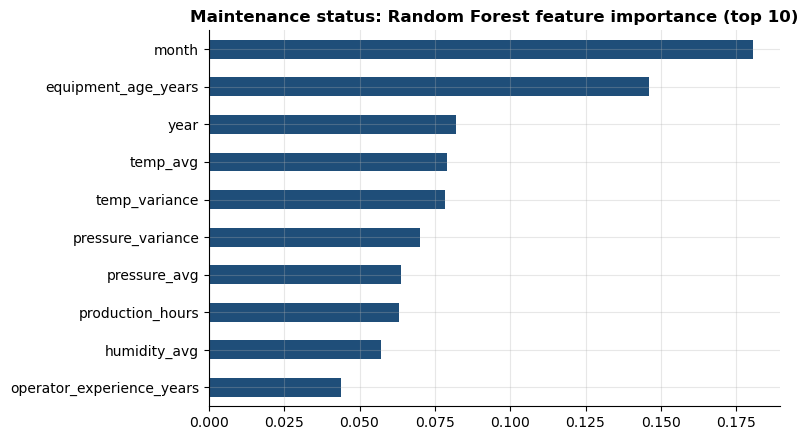

In [465]:
best_b = max(["Logistic Regression", "Random Forest"], key=lambda m: status_results[m]["Macro F1"])  # highest macro F1 wins
imp_b = pd.Series(status_models["Random Forest"][-1].feature_importances_, index=Xb.columns).sort_values(ascending=False)  # importance per input
print("Chosen:", best_b, "| top inputs:", imp_b.head(3).round(3).to_dict())  # choice and three strongest inputs
fig, ax = plt.subplots(figsize=(8, 4.5))                                    # one chart
imp_b.head(10).iloc[::-1].plot.barh(ax=ax, color=PRIMARY)                   # top 10, largest at the top
ax.set_title("Maintenance status: Random Forest feature importance (top 10)")
plt.tight_layout(); plt.show()                                              # display the chart

**Output:** the bars show the Random Forest's feature importance. The **month and year of production** and **equipment age** lead by a wide margin. Maintenance status follows the calendar of the service schedule more than the process readings. The exact values are printed above the chart.

**Comparison and choice — maintenance status:**

| Model | Macro F1 | Recall (Critical) |
|---|---|---|
| Baseline (always Current) | 0.317 | 0.000 |
| Logistic Regression | 0.259 | 0.632 |
| **Random Forest** | **0.501** | 0.242 |

**Chosen: Random Forest** (highest macro F1). If catching Critical equipment matters more than overall accuracy, Logistic Regression is the alternative: it finds 63% of Critical batches, against 24% for Random Forest.

# 05 Process control and the rise since 2019 (Module C)

**Purpose.** Check whether process conditions stay in control, whether out-of-control readings
come before failures, whether assay results are capable of meeting specification, and how much of
the rise in failures since 2019 is explained by the measured factors.

**Control limits** are set from passed batches up to 2021, so recent drift cannot distort them.
A reading is out of control when it lies outside mean plus or minus three standard deviations for
its manufacturing section. Variance measures use an upper limit only.

In [468]:
# Setup: make the project package importable and apply the shared plot style.
import sys
import warnings
from pathlib import Path

import os


def _find_project_root() -> Path:
    """Locate the project folder (the one containing src/config.py).

    Checks the BQ_PROJECT_ROOT environment variable first, then the current folder
    and each of its parents, so the notebook runs from any working directory.
    """
    env_root = os.environ.get("BQ_PROJECT_ROOT")
    if env_root:
        return Path(env_root).resolve()
    here = Path.cwd().resolve()
    for candidate in [here, *here.parents]:
        if (candidate / "src" / "config.py").exists():
            return candidate
    raise FileNotFoundError(
        "Could not find the project folder (the one containing src/config.py). "
        "Open the notebook from inside the project, or set BQ_PROJECT_ROOT to its path."
    )


ROOT = _find_project_root()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from src.config import TARGET_COL, MIN_RECALL, MIN_PRECISION, ROC_AUC_TARGET
from src.data_io import load_processed
from src.plotting import set_plot_style, save_figure, PRIMARY, ALERT, ACCENT, POSITIVE, NEUTRAL

warnings.filterwarnings("ignore")
set_plot_style()
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 220)
pd.set_option("display.max_colwidth", 80)
print("Project root:", ROOT)

Project root: /Users/apple/Desktop/Capstone-Project


In [469]:
# Load the cleaned tables written by the cleaning step (notebook 01 or the pipeline).
batches = load_processed("batches")
sales = load_processed("sales")
inventory = load_processed("inventory")
print(f"Batches: {len(batches):,} | Sales lines: {len(sales):,} | Inventory movements: {len(inventory):,}")

Batches: 60,000 | Sales lines: 150,000 | Inventory movements: 162,000


## 1. Control limits from in-control history

In [471]:
from src.process_control import control_limits, flag_out_of_control, within_limits_share

limits = control_limits(batches)
display(limits.round(3).set_index(["manufacturing_section", "variable"]).head(10))
flags = flag_out_of_control(batches, limits)

baseline_n    mean     sd     lcl     ucl
manufacturing_section variable                                                    
Creams & Ointments    temp_avg                 1064  21.984  0.850  19.434  24.535
                      pressure_avg             1061   0.900  0.043   0.771   1.029
                      humidity_avg             1061  50.891  5.099  35.593  66.190
                      temp_variance            1054   0.383  0.405   0.000   1.598
                      pressure_variance        1053   0.045  0.039   0.000   0.163
Injectables           temp_avg                  694  20.839  0.603  19.029  22.648
                      pressure_avg              696   1.199  0.060   1.019   1.379
                      humidity_avg              694  48.989  3.953  37.130  60.847
                      temp_variance             697   0.229  0.186   0.000   0.786
                      pressure_variance         697   0.044  0.038   0.000   0.158

**Output:** control limits (mean ± 3 SD) for five process readings in each section, built from passed batches up to 2021. For example, Injectables temperature runs from 19.0 to 22.6 °C.

## 2. Control chart: temperature on the largest machine

The chart shows every batch on one machine over time. Limits come from the section's in-control
history. Red points are failed batches. Points outside the limits are the out-of-control signals
that the lead-time analysis tests.

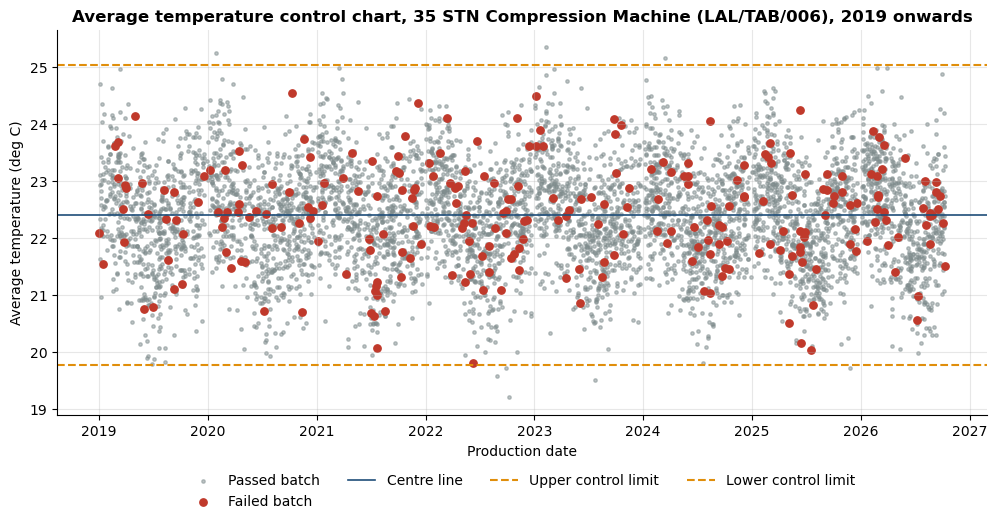

Batches shown: 5,895; failed: 262; out-of-control temperature readings: 8


In [474]:
machine = batches["equipment_id"].value_counts().idxmax()
name = batches.loc[batches["equipment_id"] == machine, "equipment_name"].iloc[0]
section = batches.loc[batches["equipment_id"] == machine, "manufacturing_section"].iloc[0]
sub = batches[batches["equipment_id"] == machine].copy()
sub = sub[sub["production_start"] >= "2019-01-01"]
lim = limits[(limits["manufacturing_section"] == section) & (limits["variable"] == "temp_avg")].iloc[0]

fig, ax = plt.subplots(figsize=(12, 5))
passed = sub[sub[TARGET_COL] == 0]
failed_b = sub[sub[TARGET_COL] == 1]
ax.scatter(passed["production_start"], passed["temp_avg"], s=6, color=NEUTRAL, alpha=0.5, label="Passed batch")
ax.scatter(failed_b["production_start"], failed_b["temp_avg"], s=28, color=ALERT, label="Failed batch")
ax.axhline(lim["mean"], color=PRIMARY, linewidth=1.2, label="Centre line")
ax.axhline(lim["ucl"], color=ACCENT, linestyle="--", label="Upper control limit")
ax.axhline(lim["lcl"], color=ACCENT, linestyle="--", label="Lower control limit")
ax.set(title=f"Average temperature control chart, {name} ({machine}), 2019 onwards",
       xlabel="Production date", ylabel="Average temperature (deg C)")
ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.12))
save_figure(fig, "14_control_chart_temperature")
plt.show()
print(f"Batches shown: {len(sub):,}; failed: {len(failed_b)}; out-of-control temperature readings: "
      f"{int(flags.loc[sub.index, 'ooc_temp_avg'].sum())}")

**Chart:** a control chart of temperature over time on the busiest machine (5,895 batches). Grey dots are passed batches, red dots are the 262 failures, and the dashed lines are the limits. Only 8 readings fall outside the limits, and the failures are spread through the band, not at its edges.

## 3. Share of readings within control limits

The proposal's target is at least 90 percent of readings within limits, and every variable meets it.
The variance measures sit lower (about 98 percent) because their distributions are skewed to the right,
so a symmetric three-sigma limit flags more of their high readings. This is noted as a limitation.

,share_within_limits,readings_out_of_control
variable,,
temp_avg,0.9978,133
pressure_avg,0.9972,170
humidity_avg,0.9974,159
temp_variance,0.9784,1293
pressure_variance,0.9800,1202


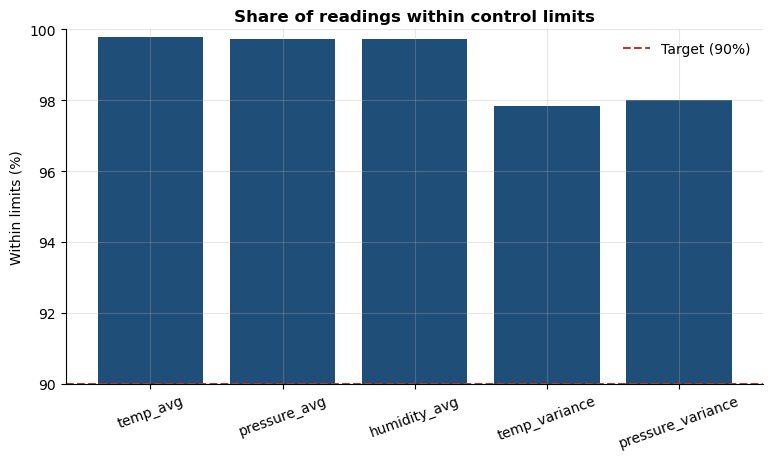

In [477]:
within = within_limits_share(flags)
display(within.round(4).set_index("variable"))

fig, ax = plt.subplots(figsize=(9, 4.6))
ax.bar(within["variable"], within["share_within_limits"] * 100, color=PRIMARY)
ax.axhline(90, color=ALERT, linestyle="--", label="Target (90%)")
ax.set_ylim(90, 100)
ax.set(title="Share of readings within control limits", ylabel="Within limits (%)")
ax.tick_params(axis="x", rotation=20)
ax.legend()
save_figure(fig, "15_within_limits")
plt.show()

**Output and chart:** the bars show the share of readings within limits. All five readings beat the 90% target: averages about 99.7–99.8%, variances about 98%.

## 4. Lead-time analysis: do failures follow warning signals?

For each batch, the test asks whether any of the five previous batches on the same machine had an
out-of-control reading. If warning signals come before failures, failed batches should show more
prior signals than passed batches.

In [480]:
from src.process_control import lead_time_analysis

lead = lead_time_analysis(batches, flags)
display(lead.round(4).set_index("outcome"))
rr = lead["relative_risk_of_prior_signal"].iloc[0]
pval = lead["chi_square_p_value"].iloc[0]
print(f"Relative risk of a prior signal before a failure: {rr:.2f} (chi-square p = {pval:.3f})")
print("Interpretation: the difference is small and not significant at the 5% level. Out-of-control "
      "readings do not give a usable early warning for these failures.")

,batches,share_with_prior_signal,relative_risk_of_prior_signal,chi_square_p_value
outcome,,,,
Passed,58125,0.2192,1.0805,0.074
Failed,1875,0.2368,1.0805,0.074


Relative risk of a prior signal before a failure: 1.08 (chi-square p = 0.074)
Interpretation: the difference is small and not significant at the 5% level. Out-of-control readings do not give a usable early warning for these failures.


**Output:** 23.7% of failed batches had a warning signal in the five previous runs, against 21.9% of passed batches (RR 1.08, p = 0.074). This is not a usable early warning.

## 5. Capability of the assay against specification

Process capability compares the spread of a result with its specification limits. Cpk of 1.33 or
more is conventionally considered capable. The assay limits of 95 to 105 percent are an assumption,
because the data carries no specification fields.

,n,mean,sd,cp,cpk,share_out_of_spec,capable_at_1_33
manufacturing_section,,,,,,,
Creams & Ointments,1480,100.0656,2.5233,0.6605,0.6518,0.0405,False
Injectables,1068,100.0409,1.8558,0.8981,0.8907,0.0131,False
Oral Liquids,12170,99.9860,2.4122,0.6909,0.6890,0.0270,False
Oral Solids,45282,99.9904,1.3291,1.2540,1.2516,0.0089,False


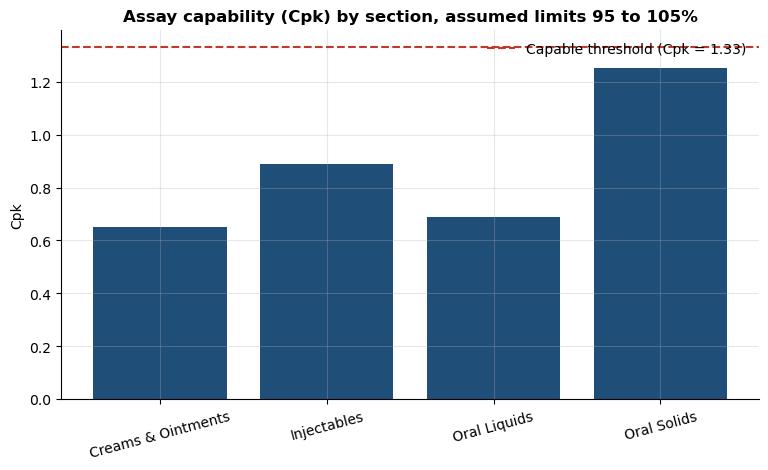

In [483]:
from src.process_control import capability

cap = capability(batches)
display(cap.round(4).set_index("manufacturing_section"))

fig, ax = plt.subplots(figsize=(9, 4.8))
ax.bar(cap["manufacturing_section"], cap["cpk"], color=PRIMARY)
ax.axhline(1.33, color=ALERT, linestyle="--", label="Capable threshold (Cpk = 1.33)")
ax.set(title="Assay capability (Cpk) by section, assumed limits 95 to 105%", ylabel="Cpk")
ax.tick_params(axis="x", rotation=15)
ax.legend()
save_figure(fig, "16_capability")
plt.show()

**Output and chart:** the bars show assay Cpk by section against the 1.33 line. No section is capable. Oral Solids comes closest (1.25), while Creams (0.65) and Oral Liquids (0.69) are well below, with 4.1% and 2.7% of batches out of spec.

## 6. The rise since 2019: how much do the measured factors explain?

The period comparison uses 2014 to 2018 against 2020 to 2025, following the proposal. 2019 is shown
separately as the turning point. The decomposition asks how much of the change in failure rate the
measured factors can account for. It does this in two ways: by the change in predicted risk given
each period's actual mix, and by the year-trend coefficient before and after adjustment.

In [486]:
from src.trend import run_trend_analysis

trend = run_trend_analysis(batches)
display(trend.periods.round(4).set_index("measure"))
display(trend.decomposition.round(4).set_index("quantity"))
display(trend.year_coefficients.round(4).set_index("model"))

period,Pre (2014-2018),Post (2020-2025)
measure,,
batches,15250.0000,22233.0000
failures,424.0000,829.0000
failure_rate,0.0278,0.0373
mean_equipment_age_years,8.0955,14.4713
share_critical,0.0050,0.0115
share_operators_0_2_years,0.1855,0.1274
share_injectables,0.0241,0.0184
share_liquid_batches,0.2292,0.2031
mean_operator_experience_years,8.5414,9.4052


,value
quantity,
"Actual failure rate, pre (2014-2018)",0.0278
"Actual failure rate, post (2020-2025)",0.0373
Actual change (percentage points),0.9484
Change predicted by measured factors (percentage points),0.5709
Share of change explained by measured factors,0.6020
Unexplained change (percentage points),0.3775


,year_coefficient,odds_ratio_per_year,p_value,share_of_trend_absorbed
model,,,,
Year trend only,0.0297,1.0302,0.000,NaN
"Year trend, adjusted for measured factors",0.0023,1.0023,0.723,0.9218


**Output:** the failure rate rose from 2.78% (2014–18) to 3.73% (2020–25), a rise of 0.95 points. The measured factors predict 0.57 points, which explains 60%. Once they are adjusted for, the year effect almost vanishes (OR 1.002 per year, p = 0.72).

### Composition: what changed between the two periods

Equipment age, operator experience and maintenance status are the measured factors that moved most.
The chart shows the share of batches in each age band in the two periods.

period,Post (2020-2025),Pre (2014-2018)
band,,
0-2 yrs,0.00,9.61
2-5 yrs,0.58,21.13
5-10 yrs,22.79,33.85
10+ yrs,76.63,35.41


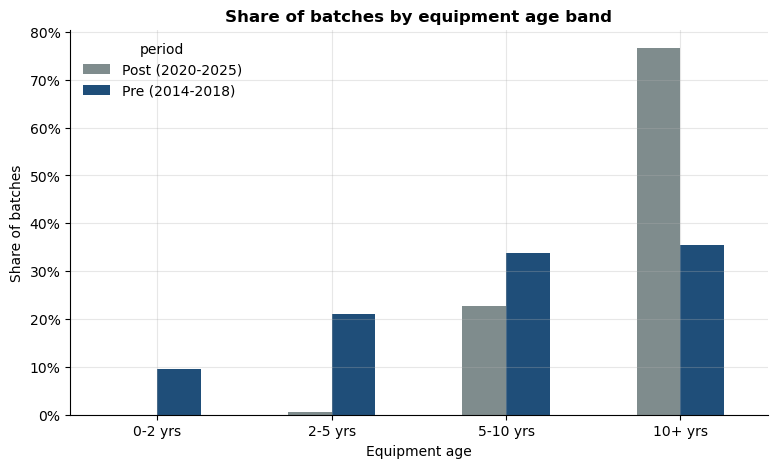

In [489]:
comp = trend.composition[trend.composition["band_type"] == "Equipment age"]
pivot = comp.pivot(index="band", columns="period", values="share").reindex(
    ["0-2 yrs", "2-5 yrs", "5-10 yrs", "10+ yrs"])
display((pivot * 100).round(2))

fig, ax = plt.subplots(figsize=(9, 5))
pivot.plot.bar(ax=ax, color=[NEUTRAL, PRIMARY])
ax.set(title="Share of batches by equipment age band", xlabel="Equipment age", ylabel="Share of batches")
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.tick_params(axis="x", rotation=0)
save_figure(fig, "17_age_composition")
plt.show()

**Output and chart:** grouped bars compare equipment-age bands in the two periods. Batches made on equipment over 10 years old rose from 35% to 77%, the main measured cause of the rise.

**Model comparison, feature importance and choice — rise since 2019**

| Model | Year odds ratio per year | p-value |
|---|---|---|
| Year trend only | 1.030 | < 0.001 |
| **Year trend, adjusted for measured factors** | **1.002** | 0.72 |

- **Chosen: the adjusted model.** Once the measured factors are included, 92% of the year trend disappears, and they explain **60%** of the rise from 2.78% to 3.73%.
- **Main driver:** equipment age. Batches made on equipment over 10 years old went from 35% to 77% of all batches, and mean equipment age rose from 8.1 to 14.5 years.

# 06 Risk view and the business back-test (Module D)

**Purpose.** Combine quality, equipment and process risk into one score for every batch, attach a
driver and a recommended action to each alert, and replay the alert rules on the 2024 to 2026 test
period. Benefits are reported as simulated, not realised.

**Score.** Each component is a percentile rank from 0 to 1. The weights are 0.6 for quality, 0.2 for
equipment and 0.2 for process. These weights are an assumption pending stakeholder sign-off.

In [493]:
# Setup: make the project package importable and apply the shared plot style.
import sys
import warnings
from pathlib import Path

import os


def _find_project_root() -> Path:
    """Locate the project folder (the one containing src/config.py).

    Checks the BQ_PROJECT_ROOT environment variable first, then the current folder
    and each of its parents, so the notebook runs from any working directory.
    """
    env_root = os.environ.get("BQ_PROJECT_ROOT")
    if env_root:
        return Path(env_root).resolve()
    here = Path.cwd().resolve()
    for candidate in [here, *here.parents]:
        if (candidate / "src" / "config.py").exists():
            return candidate
    raise FileNotFoundError(
        "Could not find the project folder (the one containing src/config.py). "
        "Open the notebook from inside the project, or set BQ_PROJECT_ROOT to its path."
    )


ROOT = _find_project_root()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from src.config import TARGET_COL, MIN_RECALL, MIN_PRECISION, ROC_AUC_TARGET
from src.data_io import load_processed
from src.plotting import set_plot_style, save_figure, PRIMARY, ALERT, ACCENT, POSITIVE, NEUTRAL

warnings.filterwarnings("ignore")
set_plot_style()
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 220)
pd.set_option("display.max_colwidth", 80)
print("Project root:", ROOT)

Project root: /Users/apple/Desktop/Capstone-Project


In [494]:
# Load the cleaned tables written by the cleaning step (notebook 01 or the pipeline).
batches = load_processed("batches")
sales = load_processed("sales")
inventory = load_processed("inventory")
print(f"Batches: {len(batches):,} | Sales lines: {len(sales):,} | Inventory movements: {len(inventory):,}")

Batches: 60,000 | Sales lines: 150,000 | Inventory movements: 162,000


## 1. Build the risk score on the test period

The score needs the adopted classifier's probability, the number of out-of-control readings per batch,
and each batch's leading driver. The pipeline produces all of these, so the notebook reads the
alert table it wrote.

In [496]:
from src.config import RISK_WEIGHTS, HIGH_RISK_TIER_SHARE

alerts = load_processed("alerts_test_period").set_index("index")
print(f"Test-period batches scored: {len(alerts):,}")
print("Weights:", RISK_WEIGHTS, "| High tier = top", f"{HIGH_RISK_TIER_SHARE:.0%}", "of batches")
display(alerts[["quality_component", "equipment_component", "process_component",
                "risk_score", "risk_tier", "classifier_flag"]].describe().round(3))

Test-period batches scored: 11,127
Weights: {'quality': 0.6, 'equipment': 0.2, 'process': 0.2} | High tier = top 10% of batches


,quality_component,equipment_component,process_component,risk_score,classifier_flag
count,11127.000,11127.000,11127.000,11127.000,11127.000
mean,0.500,0.282,0.012,0.359,0.755
std,0.289,0.172,0.049,0.193,0.430
min,0.000,0.000,0.000,0.003,0.000
25%,0.250,0.147,0.000,0.195,1.000
50%,0.500,0.284,0.000,0.357,1.000
75%,0.750,0.432,0.000,0.522,1.000
max,1.000,0.912,0.400,0.822,1.000


**Output:** 11,127 test-period batches scored with weights 0.6 quality, 0.2 equipment and 0.2 process. The mean risk score is 0.36 (range 0.003–0.82). The process component is almost always 0, because out-of-control readings are rare.

## 2. Score distribution and tiers

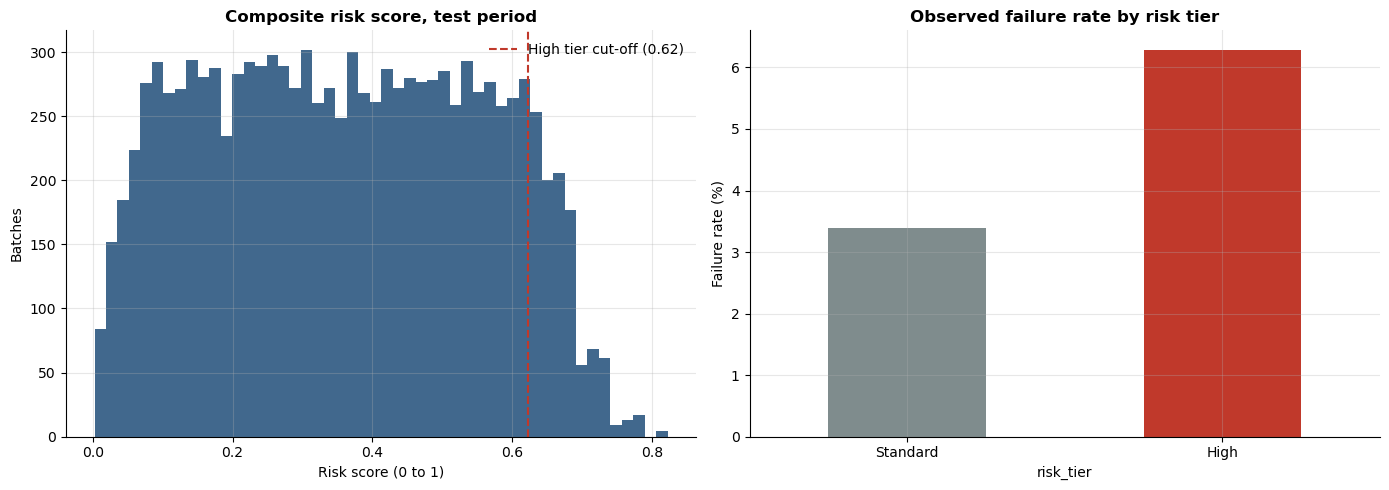

,failure_rate
risk_tier,
Standard,0.0339
High,0.0629


In [499]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].hist(alerts["risk_score"], bins=50, color=PRIMARY, alpha=0.85)
cut = alerts.loc[alerts["risk_tier"] == "High", "risk_score"].min()
axes[0].axvline(cut, color=ALERT, linestyle="--", label=f"High tier cut-off ({cut:.2f})")
axes[0].set(title="Composite risk score, test period", xlabel="Risk score (0 to 1)", ylabel="Batches")
axes[0].legend()
tier_rates = alerts.groupby("risk_tier")["batch_passed"].apply(lambda s: 1 - s.mean()).reindex(["Standard", "High"])
tier_rates.mul(100).plot.bar(ax=axes[1], color=[NEUTRAL, ALERT])
axes[1].set(title="Observed failure rate by risk tier", ylabel="Failure rate (%)")
axes[1].tick_params(axis="x", rotation=0)
fig.tight_layout()
save_figure(fig, "18_risk_distribution")
plt.show()
display(tier_rates.rename("failure_rate").to_frame().round(4))

**Charts:** left, a histogram of risk scores with the High-tier cut-off (top 10%). Right, the failure rate by tier: High fails at 6.3%, against 3.4% for Standard.

## 3. The back-test: what would each rule have caught?

The two rules are compared on the same 2024 to 2026 batches. The first is the classifier alert at its
validation-set threshold. The second is the High tier of the composite score. The comparison reports the
share of failures caught, the share of batches flagged, the lift, and the batch volume that would have
been held. Volumes are kept in kilograms and litres separately, because the data has no monetary value.

rule,Classifier alert at 80% recall target,High risk tier (top 10% by composite score)
batches_flagged,8.398000e+03,1113.0000
share_of_batches_flagged,7.547000e-01,0.1000
failures_in_period,4.090000e+02,409.0000
failures_caught,3.350000e+02,70.0000
share_of_failures_caught,8.191000e-01,0.1711
failure_rate_flagged,3.990000e-02,0.0629
failure_rate_not_flagged,2.710000e-02,0.0339
lift_flagged_vs_base,1.085200e+00,1.7110
volume_flagged_kg,9.951500e+05,65770.0000
volume_flagged_litres,1.280560e+06,170320.0000


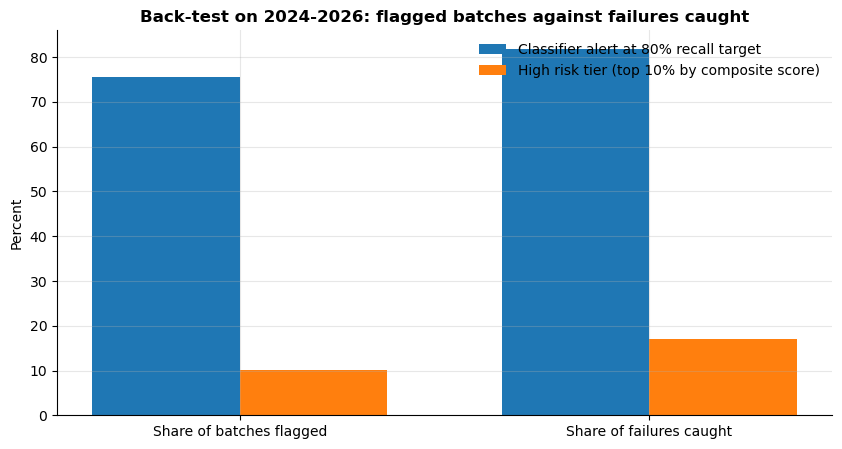

In [502]:
summary = pd.read_csv(ROOT / "reports" / "tables" / "backtest_summary.csv").set_index("rule")
display(summary.round(4).T)

fig, ax = plt.subplots(figsize=(10, 5))
width = 0.36
labels = ["Share of batches flagged", "Share of failures caught"]
for i, (rule, row) in enumerate(summary.iterrows()):
    values = [row["share_of_batches_flagged"] * 100, row["share_of_failures_caught"] * 100]
    ax.bar(np.arange(2) + (i - 0.5) * width, values, width, label=rule)
ax.set_xticks(range(2), labels)
ax.set(title="Back-test on 2024-2026: flagged batches against failures caught", ylabel="Percent")
ax.legend()
save_figure(fig, "19_backtest_rules")
plt.show()

**Output:** grouped bars compare the two rules. The classifier alert catches 82% of failures but flags 75% of batches (lift 1.09). The High tier flags only 10% of batches and catches 17% of failures, at 1.71× the base rate.

### Stability by year

A rule that works only in one year would be unsafe to rely on. The table repeats the back-test for each year.

In [505]:
by_year = pd.read_csv(ROOT / "reports" / "tables" / "backtest_by_year.csv").set_index("year")
display(by_year[["batches_flagged", "failures_in_period", "failures_caught",
                 "share_of_failures_caught", "failure_rate_flagged", "failure_rate_not_flagged"]].round(4))

,batches_flagged,failures_in_period,failures_caught,share_of_failures_caught,failure_rate_flagged,failure_rate_not_flagged
year,,,,,,
2024,2884,142,122,0.8592,0.0423,0.0204
2025,3038,156,124,0.7949,0.0408,0.0317
2026,2476,111,89,0.8018,0.0359,0.0297


**Output:** the classifier rule is stable across years, catching 79–86% of failures in each of 2024, 2025 and 2026.

### Critical equipment: does the flag line up with the maintenance signal?

In [508]:
crit = pd.read_csv(ROOT / "reports" / "tables" / "backtest_critical_equipment.csv").set_index("group")
display(crit.round(4))
print("Small numbers: the Critical group in the test period has few batches, so the rate is indicative only.")

,batches,failures,failure_rate
group,,,
Critical maintenance status,79,8,0.1013
Current or Due Soon,11048,401,0.0363


Small numbers: the Critical group in the test period has few batches, so the rate is indicative only.


**Output:** in the test period, Critical batches failed at 10.1%, against 3.6% for the rest. That is only 79 batches, so the figure is indicative.

## 4. Alert list for the High tier

Each alert shows the batch, its leading driver, and the recommended action. Operator identifiers are
pseudonymised. The full alert list is exported for the dashboard and for QA.

In [511]:
high = alerts[alerts["risk_tier"] == "High"].sort_values("risk_score", ascending=False)
cols = ["batch_id", "production_start", "drug_name", "equipment_id", "maintenance_status",
        "risk_score", "primary_driver", "recommended_action", "operator_pseudo_id"]
display(high[cols].head(15).round(3).set_index("batch_id"))

export_path = ROOT / "reports" / "tables" / "high_risk_alerts_test_period.csv"
high[cols + ["batch_passed", "failure_mode"]].to_csv(export_path, index=False)
print(f"High-tier alerts exported: {len(high):,} rows -> {export_path.relative_to(ROOT)}")

,production_start,drug_name,equipment_id,maintenance_status,risk_score,primary_driver,recommended_action,operator_pseudo_id
batch_id,,,,,,,,
SUS-24-0008,2024-02-19,Sucra Suspension,LAL/LIQ/003,Critical,0.822,Maintenance: Critical,Complete overdue maintenance on this equipment and confirm calibration befor...,OP-AE9BB187
SUS-24-0009,2024-02-27,Sucra Suspension,LAL/LIQ/003,Critical,0.822,Maintenance: Critical,Complete overdue maintenance on this equipment and confirm calibration befor...,OP-309E99D4
LRS-24-0015,2024-02-28,Lorata Syrup,LAL/LIQ/003,Critical,0.822,Temperature variance,Review the process trend for this run and verify environmental controls befo...,OP-309E99D4
ALS-24-0027,2024-03-11,Altoa Suspension,LAL/LIQ/003,Critical,0.821,Maintenance: Critical,Complete overdue maintenance on this equipment and confirm calibration befor...,OP-AC3BB1BD
AB3-26-0023,2026-07-21,Altoa 300mg Bolus,LAL/TAB/006,Due Soon,0.785,Equipment age (years),Complete overdue maintenance on this equipment and confirm calibration befor...,OP-06EB8D09
ZRS-26-0031,2026-04-16,Zerocin Suspension,LAL/LIQ/003,Due Soon,0.784,Temperature variance,Review the process trend for this run and verify environmental controls befo...,OP-DB1FDAD5
ALS-24-0021,2024-02-26,Altoa Suspension,LAL/LIQ/003,Critical,0.781,Maintenance: Critical,Complete overdue maintenance on this equipment and confirm calibration befor...,OP-96306D7B
ZRS-24-0007,2024-02-19,Zerocin Suspension,LAL/LIQ/003,Critical,0.781,Maintenance: Critical,Complete overdue maintenance on this equipment and confirm calibration befor...,OP-8924844D
SUS-25-0025,2025-10-23,Sucra Suspension,LAL/LIQ/003,Due Soon,0.781,Equipment age (years),Complete overdue maintenance on this equipment and confirm calibration befor...,OP-AE9BB187


High-tier alerts exported: 1,113 rows -> reports/tables/high_risk_alerts_test_period.csv


**Output:** the High-tier alert list, led by Critical-status batches on LAL/LIQ/003 (score 0.82). In total, 1,113 alerts are exported for QA.

**Model comparison, feature importance and choice — risk view**

| Rule | Batches flagged | Failures caught | Failure rate flagged | Lift |
|---|---|---|---|---|
| Classifier alert (80% recall target) | 75.5% | 81.9% | 3.99% | 1.09 |
| **High risk tier (top 10% by score)** | **10.0%** | 17.1% | **6.29%** | **1.71** |

- **Chosen: the High risk tier**, for targeting extra checks. It reaches 1.7 times the average failure rate while holding only 10% of the volume.
- **Weights (importance):** quality 0.6, equipment 0.2, process 0.2. The process component is almost always 0, so the tier is driven mainly by the classifier probability and equipment age.

## 5. What this notebook established

* The composite score's High tier concentrates failures more than the classifier alert does, at a much
  smaller batch volume. The tier is selected mainly by the classifier probability, so its lift is only as
  good as the classifier's ranking. The leading driver shown to QA is most often equipment age, which is
  a stable and explainable signal.
* The classifier's alert at the 80 percent recall target flags most batches and gives little lift, so it
  is not recommended as an automatic hold rule.
* Simulated savings are not reported, because the data has no monetary value. Volumes are reported instead.

# 07 Demand forecasting (optional module E)

**Purpose.** Forecast monthly unit demand from the sales history, and compare three methods against the
seasonal-naive baseline on the most recent 12 months. The proposal's target is a WAPE at least 15 percent
better than the baseline.

**Scope.** Monthly forecasts only. Weekly demand is listed as an extension in the tracker. Cancelled
orders are excluded, because they are not real demand.

In [516]:
# Setup: make the project package importable and apply the shared plot style.
import sys
import warnings
from pathlib import Path

import os


def _find_project_root() -> Path:
    """Locate the project folder (the one containing src/config.py).

    Checks the BQ_PROJECT_ROOT environment variable first, then the current folder
    and each of its parents, so the notebook runs from any working directory.
    """
    env_root = os.environ.get("BQ_PROJECT_ROOT")
    if env_root:
        return Path(env_root).resolve()
    here = Path.cwd().resolve()
    for candidate in [here, *here.parents]:
        if (candidate / "src" / "config.py").exists():
            return candidate
    raise FileNotFoundError(
        "Could not find the project folder (the one containing src/config.py). "
        "Open the notebook from inside the project, or set BQ_PROJECT_ROOT to its path."
    )


ROOT = _find_project_root()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from src.config import TARGET_COL, MIN_RECALL, MIN_PRECISION, ROC_AUC_TARGET
from src.data_io import load_processed
from src.plotting import set_plot_style, save_figure, PRIMARY, ALERT, ACCENT, POSITIVE, NEUTRAL

warnings.filterwarnings("ignore")
set_plot_style()
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 220)
pd.set_option("display.max_colwidth", 80)
print("Project root:", ROOT)

Project root: /Users/apple/Desktop/Capstone-Project


In [517]:
# Load the cleaned tables written by the cleaning step (notebook 01 or the pipeline).
batches = load_processed("batches")
sales = load_processed("sales")
inventory = load_processed("inventory")
print(f"Batches: {len(batches):,} | Sales lines: {len(sales):,} | Inventory movements: {len(inventory):,}")

Batches: 60,000 | Sales lines: 150,000 | Inventory movements: 162,000


## 1. Monthly demand series

Units sold per month are aggregated by product category. The total is the sum of all categories.

Product_Category,Clinical_Supplies,Consumables,Equipment,Glassware,PPE,Reagents,Total
year_month,,,,,,,
2025-07-01,3762,4979,272,3575,3786,3884,20258
2025-08-01,3325,3364,262,3126,3643,4370,18090
2025-09-01,4418,4625,294,4323,3582,3973,21215
2025-10-01,3839,4635,343,5161,5173,4517,23668
2025-11-01,4605,5146,318,4007,4017,4200,22293
2025-12-01,5117,4035,359,4468,5577,4526,24082


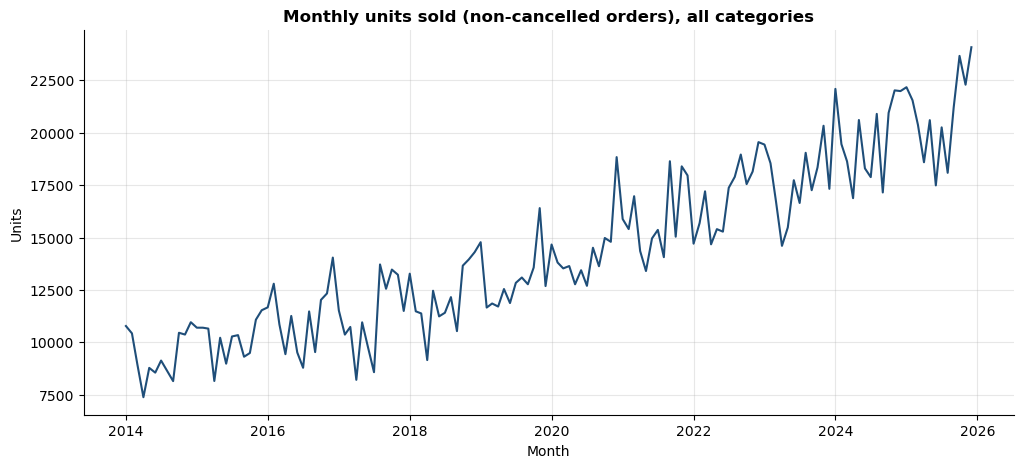

In [519]:
from src.forecasting import monthly_demand

demand = monthly_demand(sales)
display(demand.tail(6).round(0))

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(demand.index, demand["Total"], color=PRIMARY)
ax.set(title="Monthly units sold (non-cancelled orders), all categories", xlabel="Month", ylabel="Units")
save_figure(fig, "20_monthly_demand")
plt.show()

**Output and chart:** the line shows total monthly units. They roughly double, from about 7,000–11,000 a month in 2014 to about 17,500–24,000 in 2025. The table shows the last six months by category; Equipment is the smallest, at about 260–360 units a month.

## 2. Seasonality

A year-by-month heatmap shows whether demand has a repeating pattern. Strong seasonality favours
seasonal methods over flat ones.

month,1,2,3,4,5,6,7,8,9,10,11,12
year,,,,,,,,,,,,
2014,10.8,10.4,8.9,7.4,8.8,8.6,9.1,8.6,8.2,10.5,10.4,11.0
2015,10.7,10.7,10.7,8.2,10.2,9.0,10.3,10.3,9.3,9.5,11.1,11.5
2016,11.7,12.8,10.9,9.4,11.3,9.5,8.8,11.5,9.5,12.0,12.3,14.0
2017,11.5,10.4,10.7,8.2,11.0,9.7,8.6,13.7,12.6,13.5,13.2,11.5
2018,13.3,11.5,11.4,9.2,12.5,11.2,11.4,12.2,10.5,13.7,14.0,14.3
2019,14.8,11.7,11.9,11.7,12.5,11.9,12.8,13.1,12.8,13.6,16.4,12.7
2020,14.7,13.8,13.5,13.6,12.8,13.4,12.7,14.5,13.6,15.0,14.8,18.8
2021,15.9,15.4,17.0,14.4,13.4,15.0,15.4,14.1,18.6,15.0,18.4,18.0
2022,14.7,15.7,17.2,14.7,15.4,15.3,17.4,17.9,19.0,17.6,18.2,19.6


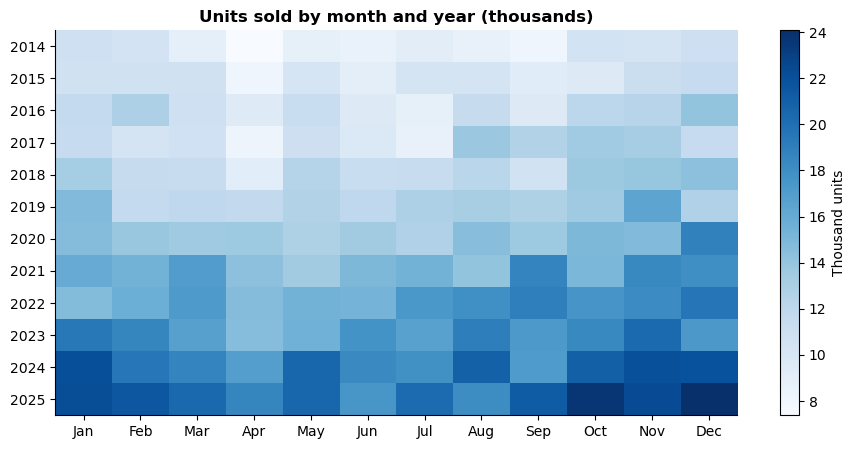

In [522]:
heat = demand["Total"].to_frame("units")
heat["year"] = heat.index.year
heat["month"] = heat.index.month
pivot = heat.pivot(index="year", columns="month", values="units")
display((pivot / 1000).round(1))

fig, ax = plt.subplots(figsize=(11, 5))
im = ax.imshow(pivot.values / 1000, cmap="Blues", aspect="auto")
ax.set_xticks(range(12), ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
ax.set_yticks(range(len(pivot.index)), pivot.index)
ax.set_title("Units sold by month and year (thousands)")
fig.colorbar(im, ax=ax, label="Thousand units")
ax.grid(False)
save_figure(fig, "21_seasonality_heatmap")
plt.show()

**Output and chart:** a heat map of units sold (thousands) by year and month. It darkens from top to bottom (growth), and October to January are usually the darkest months, with April usually the lightest.

## 3. Forecast accuracy on the 12-month holdout

The series is split at the last 12 months. Each method is fitted on the earlier history and forecasts the
holdout. WAPE is the main metric: total absolute error divided by total actual demand.

In [525]:
from src.forecasting import evaluate_series

accuracy_table, forecast_table = evaluate_series(demand["Total"])
display(accuracy_table.round(4))

base = accuracy_table.loc["Seasonal naive (baseline)", "WAPE"]
best = accuracy_table["WAPE"].idxmin()
gain = accuracy_table.loc[best, "WAPE_improvement_vs_baseline"]
status = "Met" if gain >= 0.15 else "Not met"
print(f"Best method: {best}. WAPE improvement over seasonal naive: {gain:.1%}. Target 15%: {status}.")

,WAPE,RMSE,Bias,WAPE_improvement_vs_baseline
method,,,,
Seasonal naive (baseline),0.0830,2099.2308,-0.0540,0.0000
Moving average (3 months),0.0825,2139.7429,0.0378,0.0053
"Holt-Winters (damped, seasonal)",0.0549,1436.0893,-0.0159,0.3377


Best method: Holt-Winters (damped, seasonal). WAPE improvement over seasonal naive: 33.8%. Target 15%: Met.


**Output:** on the last 12 months, Holt-Winters has WAPE 5.5%, against 8.3% for seasonal-naive, a 33.8% gain that passes the 15% target. The 3-month moving average barely beats the baseline (0.5%). The warning is a statsmodels fitting note, not an error.

## 4. Forecast against actual demand

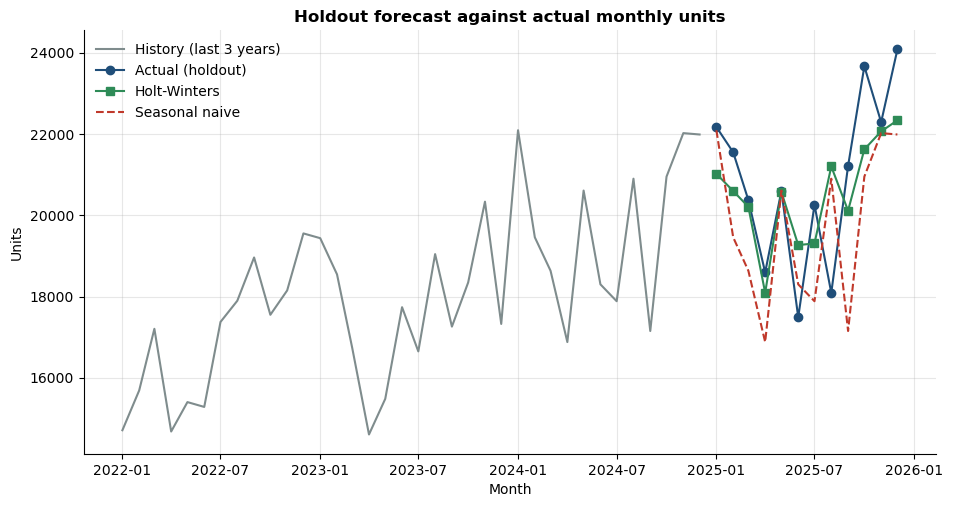

In [528]:
fig, ax = plt.subplots(figsize=(11, 5.5))
hist = demand["Total"].iloc[:-len(forecast_table)]
ax.plot(hist.index[-36:], hist.iloc[-36:], color=NEUTRAL, label="History (last 3 years)")
ft = forecast_table.set_index("month")
ax.plot(ft.index, ft["actual"], color=PRIMARY, marker="o", label="Actual (holdout)")
ax.plot(ft.index, ft["Holt-Winters (damped, seasonal)"], color=POSITIVE, marker="s", label="Holt-Winters")
ax.plot(ft.index, ft["Seasonal naive (baseline)"], color=ALERT, linestyle="--", label="Seasonal naive")
ax.set(title="Holdout forecast against actual monthly units", xlabel="Month", ylabel="Units")
ax.legend()
save_figure(fig, "22_forecast_holdout")
plt.show()

**Chart:** the last three years of history (grey) with the 12-month holdout. Holt-Winters (green) follows the actual line (blue) closely, while seasonal-naive (red dashed) runs below it most months.

**Model comparison, feature importance and choice — monthly demand**

| Method | WAPE | Bias | Gain vs baseline |
|---|---|---|---|
| Seasonal naive (baseline) | 8.30% | −5.4% | – |
| Moving average (3 months) | 8.25% | +3.8% | 0.5% |
| **Holt-Winters (damped, seasonal)** | **5.49%** | **−1.6%** | **33.8%** |

- **Chosen: Holt-Winters.** It has the lowest error, the smallest bias, and it meets the 15% target.
- **Feature importance:** not applicable. These methods use only the demand series itself (level, trend and season), with no input features.

## 5. Reading the result

Seasonal-naive repeats last year's pattern exactly, which is hard to beat when the pattern is stable.
Holt-Winters learns both trend and seasonality, and damps the trend so the forecast does not run away.
A method that is best on total demand may still be weak on individual categories. Category-level accuracy
is a natural next step before any reorder decisions are made.

# 6. Weekly demand per product
The monthly forecast above works on total demand. Here the forecast is made **per product, per week**, where 47.6% of weeks have no sale. Models: seasonal-naive (baseline), 12-week moving average, Croston-SBA, Linear Regression; metric WAPE with bias within ±10%. Uses `demand_panel` from Stage 3.

In [533]:
from sklearn.pipeline import make_pipeline                                  # chain imputation and model
from sklearn.linear_model import LinearRegression                           # linear regression
c_features = ["lag1", "lag2", "lag4", "lag52", "roll12", "std12", "week_of_year"]  # past demand and calendar inputs
dc = demand_panel.dropna(subset=c_features + ["sba"]).sort_values(["week", "Product_ID"]).reset_index(drop=True)  # time order
Xc_tr, Xc_te, yc_tr, yc_te = train_test_split(dc[c_features], dc["units"], test_size=0.2, shuffle=False)  # last 20% of weeks = test
forecasts = {"Seasonal-naive (baseline)": dc.loc[Xc_te.index, "lag52"],     # same week last year
             "Moving average (12 weeks)": dc.loc[Xc_te.index, "roll12"],    # average of the last 12 weeks
             "Croston-SBA": dc.loc[Xc_te.index, "sba"],                     # built for intermittent demand
             "Linear Regression": LinearRegression().fit(Xc_tr, yc_tr).predict(Xc_te).clip(0)}
demand_results = pd.DataFrame({name: {"WAPE (%)": 100 * np.abs(yc_te - f).sum() / yc_te.sum(),  # total error / total demand
                                      "Bias (%)": 100 * (np.sum(f) - yc_te.sum()) / yc_te.sum()}  # + over, - under
                               for name, f in forecasts.items()}).T
demand_results["Gain vs seasonal-naive (%)"] = 100 * (1 - demand_results["WAPE (%)"] / demand_results.loc["Seasonal-naive (baseline)", "WAPE (%)"])
best_c = demand_results[demand_results["Bias (%)"].abs() <= 10]["WAPE (%)"].idxmin()  # lowest error among unbiased models
display(demand_results.round(1)); print("Chosen (lowest WAPE with bias within ±10%):", best_c)

,WAPE (%),Bias (%),Gain vs seasonal-naive (%)
Seasonal-naive (baseline),143.2,-6.9,0.0
Moving average (12 weeks),120.2,-1.0,16.1
Croston-SBA,115.0,-5.9,19.7
Linear Regression,110.6,-21.6,22.8


Chosen (lowest WAPE with bias within ±10%): Croston-SBA


**Output:** product-week demand is very hard to forecast, and all errors exceed 100% of demand. **Croston-SBA** is chosen: WAPE 115.0%, 19.7% better than seasonal-naive, with only −5.9% bias. Linear Regression has a lower error (110.6%) but under-forecasts by 21.6%, which would cause stock-outs.

Chosen: Croston-SBA | Linear Regression top inputs (MAE rise, units): {'roll12': 0.72, 'lag52': 0.04, 'week_of_year': 0.01}


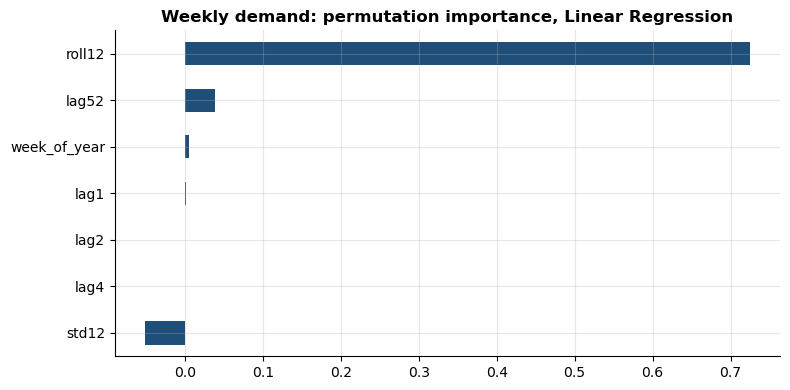

In [535]:
from sklearn.inspection import permutation_importance                       # error increase when one input is shuffled

lr_c = LinearRegression().fit(Xc_tr, yc_tr)                                 # refit the regression to inspect it
pi_c = permutation_importance(lr_c, Xc_te, yc_te, scoring="neg_mean_absolute_error", n_repeats=3, random_state=42)
imp_c = pd.Series(pi_c.importances_mean, index=c_features).sort_values(ascending=False)  # rise in MAE (units) per input
print("Chosen:", best_c, "| Linear Regression top inputs (MAE rise, units):", imp_c.head(3).round(2).to_dict())
fig, ax = plt.subplots(figsize=(8, 4))                                      # one chart
imp_c.iloc[::-1].plot.barh(ax=ax, color=PRIMARY)                            # all seven inputs
ax.set_title("Weekly demand: permutation importance, Linear Regression")
plt.tight_layout(); plt.show()                                              # display the chart

**Output:** Croston-SBA, the chosen model, uses only each product's own sales history, so it has no feature importance. The chart shows the Linear Regression instead. The **12-week average** (`roll12`) is by far its most useful input: shuffling it raises the error by about 0.7 units per product-week. Demand 52 weeks earlier and the week of the year add very little.

**Comparison and choice — weekly demand:**

| Model | WAPE | Bias | Gain vs seasonal-naive |
|---|---|---|---|
| Seasonal-naive (baseline) | 143.2% | −6.9% | – |
| Moving average (12 weeks) | 120.2% | −1.0% | 16.1% |
| **Croston-SBA** | **115.0%** | **−5.9%** | **19.7%** |
| Linear Regression | 110.6% | −21.6% | 22.8% |

**Chosen: Croston-SBA**, which has the lowest error among models with bias within ±10%. Linear Regression is rejected because it under-forecasts by 22%.

# 08 Inventory: stock-out risk, product groups and reorder policy
**Purpose.** Use the weekly stock table from Stage 3 to warn of stock-outs, group products by demand pattern, and set reorder points. This module has no counterpart in the original notebooks.

# 1. Stock-out risk within 14 days
Models: random baseline, Logistic Regression, Random Forest, Gradient Boosting; metric PR-AUC, with the alert threshold set at recall 0.80.

In [539]:
from sklearn.pipeline import make_pipeline                                  # chain imputation and model
from sklearn.linear_model import LinearRegression                           # linear regression
from sklearn.ensemble import HistGradientBoostingClassifier                 # gradient boosting
from sklearn.metrics import average_precision_score, precision_recall_curve  # ranking quality for rare events

d_features = ["stock", "sold", "roll4", "roll12", "rec4", "cover_weeks"]    # stock position and recent demand
dd = stock_panel[(stock_panel["stock"] > 0) & stock_panel["stockout_2w"].notna() & (stock_panel["week"] >= all_weeks[12])]
dd = dd.sort_values(["week", "Branch_Code", "Product_ID"]).reset_index(drop=True)  # in stock now, time order
Xd = pd.get_dummies(dd[d_features + ["Branch_Code", "category"]], columns=["Branch_Code", "category"], dtype=float)
Xd_tr, Xd_te, yd_tr, yd_te = train_test_split(Xd, dd["stockout_2w"].astype(int), test_size=0.2, shuffle=False)  # last 20% of weeks
stockout_models = {"Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=2000)),
                   "Random Forest": RandomForestClassifier(n_estimators=100, max_depth=10, class_weight="balanced", n_jobs=-1, random_state=42),
                   "Gradient Boosting": HistGradientBoostingClassifier(max_iter=200, learning_rate=0.05, class_weight="balanced", random_state=42)}
stockout_prob = {name: m.fit(Xd_tr, yd_tr).predict_proba(Xd_te)[:, 1] for name, m in stockout_models.items()}  # P(stock-out)
stockout_results = pd.Series({"Baseline (random)": yd_te.mean(), **{n: average_precision_score(yd_te, p) for n, p in stockout_prob.items()}}, name="PR-AUC")
display(stockout_results.to_frame().assign(times_random=lambda d: d["PR-AUC"] / yd_te.mean()).round(3))
best_d = stockout_results.drop("Baseline (random)").idxmax()                # highest PR-AUC
prec, rec, thr = precision_recall_curve(yd_te, stockout_prob[best_d])       # precision and recall at every threshold
k = np.where(rec[:-1] >= 0.80)[0][-1]                                       # highest threshold keeping recall >= 0.80
print(f"Chosen: {best_d}. At threshold {thr[k]:.3f}: recall {rec[k]:.2f}, precision {prec[k]:.2f}, "
      f"{(stockout_prob[best_d] >= thr[k]).sum():,} alerts for {yd_te.sum()} stock-outs")

,PR-AUC,times_random
Baseline (random),0.001,1.000
Logistic Regression,0.265,196.079
Random Forest,0.209,154.383
Gradient Boosting,0.278,205.412


Chosen: Gradient Boosting. At threshold 0.748: recall 0.80, precision 0.11, 1,109 alerts for 156 stock-outs


**Output:** Gradient Boosting ranks stock-outs best (PR-AUC **0.278**, 205 times random, where stock-outs are only 0.1% of in-stock weeks). Logistic Regression is close behind (0.265), and Random Forest is weakest (0.209). At threshold 0.748, the chosen model catches 80% of the 156 test stock-outs with 1,109 alerts, so about 1 alert in 9 is a real stock-out.

Chosen: Gradient Boosting | top inputs (PR-AUC drop): {'stock': 0.268, 'cover_weeks': 0.258, 'Branch_Code_BR01': 0.174}


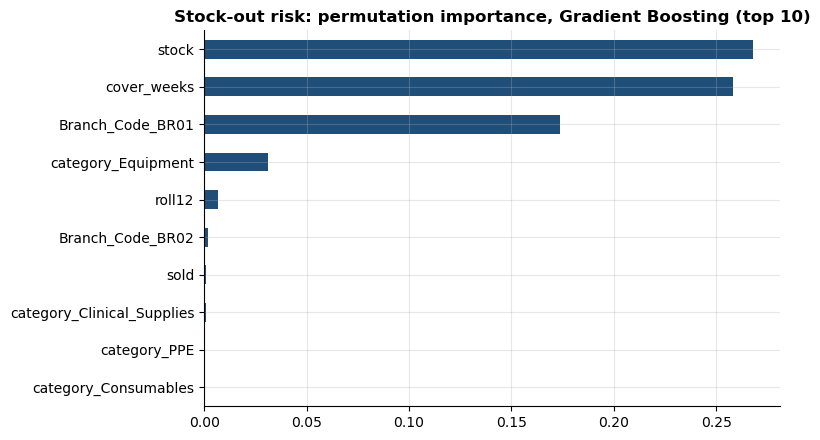

In [541]:
from sklearn.inspection import permutation_importance                       # PR-AUC drop when one input is shuffled

pi_d = permutation_importance(stockout_models[best_d], Xd_te, yd_te, scoring="average_precision", n_repeats=3, random_state=42, n_jobs=-1)
imp_d = pd.Series(pi_d.importances_mean, index=Xd.columns).sort_values(ascending=False)  # drop in PR-AUC per input
print("Chosen:", best_d, "| top inputs (PR-AUC drop):", imp_d.head(3).round(3).to_dict())
fig, ax = plt.subplots(figsize=(8, 4.5))                                    # one chart
imp_d.head(10).iloc[::-1].plot.barh(ax=ax, color=PRIMARY)                   # top 10, largest at the top
ax.set_title(f"Stock-out risk: permutation importance, {best_d} (top 10)")
plt.tight_layout(); plt.show()                                              # display the chart

**Output:** the bars show how much PR-AUC drops when each input is shuffled. **Current stock** and **weeks of cover** lead by a wide margin, followed by the branch flag for **BR01**, the busiest branch. Recent sales and receipts add less. The exact values are printed above the chart.

**Comparison and choice — stock-out risk:**

| Model | PR-AUC | Times random |
|---|---|---|
| Baseline (random) | 0.001 | 1 |
| Logistic Regression | 0.265 | 196 |
| Random Forest | 0.209 | 154 |
| **Gradient Boosting** | **0.278** | **205** |

**Chosen: Gradient Boosting** (highest PR-AUC), with its alert threshold set where recall reaches 0.80.

## 2. Product groups (K-Means)
Products are grouped by average weekly demand, demand variability, share of zero weeks, sales value and price. The number of groups is chosen by the silhouette score on held-out products.

In [544]:
from sklearn.cluster import KMeans                                          # clustering
from sklearn.metrics import silhouette_score                                # how well groups separate

wk = demand_panel.pivot(index="Product_ID", columns="week", values="units")  # products x weeks of units sold
pf = pd.DataFrame({"mean_weekly_units": wk.mean(axis=1),                    # average weekly demand
                   "cv_weekly_units": wk.std(axis=1) / wk.mean(axis=1),     # how uneven demand is
                   "zero_weeks_%": 100 * (wk == 0).mean(axis=1),            # share of weeks with no sale
                   "net_sales_kes": delivered.groupby("Product_ID")["Net_Amount_Excl_VAT_KES"].sum(),  # value sold
                   "avg_price": delivered.groupby("Product_ID")["Unit_Price_KES"].mean()})  # one row per product
Xe = StandardScaler().fit_transform(np.log1p(pf))                           # log for skewed values, then standardise
Xe_tr, Xe_te = train_test_split(Xe, test_size=0.2, random_state=42)         # fit on 80%, score on the held-out 20%
sil = {k: silhouette_score(Xe_te, KMeans(k, n_init=10, random_state=42).fit(Xe_tr).predict(Xe_te)) for k in range(2, 7)}
best_k = max(sil, key=sil.get)                                              # highest silhouette
pf["group"] = KMeans(best_k, n_init=10, random_state=42).fit(Xe_tr).predict(Xe)  # group for every product
print("Silhouette by k:", {k: round(v, 3) for k, v in sil.items()}, "| chosen k =", best_k)
display(pf.assign(category=category_of).groupby("group").agg(products=("avg_price", "size"), median_weekly_units=("mean_weekly_units", "median"),
        median_price_kes=("avg_price", "median"), net_sales_kes_m=("net_sales_kes", lambda s: s.sum() / 1e6),
        main_category=("category", lambda s: s.mode()[0])).round(1))

Silhouette by k: {2: 0.54, 3: 0.311, 4: 0.313, 5: 0.352, 6: 0.271} | chosen k = 2


,products,median_weekly_units,median_price_kes,net_sales_kes_m,main_category
group,,,,,
0,250,13.0,1773.6,8916.8,Clinical_Supplies
1,50,1.0,32418.4,2782.6,Equipment


**Output:** **two groups** separate best (silhouette 0.54; k = 3–6 score only 0.27–0.35). The **fast group** has 250 cheap items: about 13 units a week, a median price of KES 1,774, and KES 8,917m of sales (76% of value). The **slow group** has 50 expensive items, mostly Equipment: about 1 unit a week, a median price of KES 32,418, and KES 2,783m of sales. Each group needs its own stock rule. The group numbers 0 and 1 can swap between runs; the sizes do not.

Chosen: K-Means, k = 2 | inputs that separate the groups most: {'mean_weekly_units': 2.67, 'cv_weekly_units': 2.53, 'avg_price': 1.33, 'net_sales_kes': 0.14, 'zero_weeks_%': 0.04}


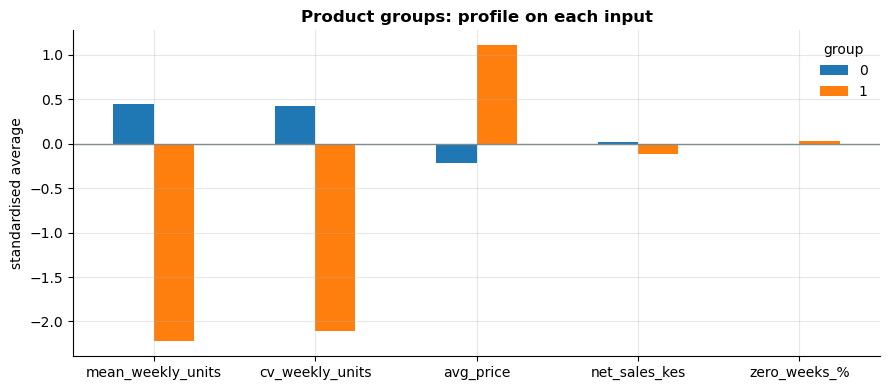

In [546]:
prof = pd.DataFrame(Xe, index=pf.index, columns=pf.columns[:5]).groupby(pf["group"]).mean()  # standardised average per group
spread = (prof.max() - prof.min()).sort_values(ascending=False)             # how far apart the groups sit on each input
print("Chosen: K-Means, k =", best_k, "| inputs that separate the groups most:", spread.round(2).to_dict())
fig, ax = plt.subplots(figsize=(9, 4))                                      # one chart
prof[spread.index].T.plot.bar(ax=ax, rot=0)                                 # one bar per group for each input
ax.axhline(0, color=NEUTRAL, linewidth=1); ax.set_ylabel("standardised average")
ax.set_title("Product groups: profile on each input")
plt.tight_layout(); plt.show()                                              # display the chart

**Output:** the chart shows each group's standardised average on the five inputs. The groups differ most on **average weekly units** (spread 2.67) and **demand variability** (2.53), then on **price** (1.33). They hardly differ on total sales value or on the share of zero weeks.

**Comparison and choice — product groups:**

| k | 2 | 3 | 4 | 5 | 6 |
|---|---|---|---|---|---|
| Silhouette | **0.540** | 0.311 | 0.313 | 0.352 | 0.271 |

**Chosen: K-Means with k = 2** (highest silhouette): a fast, cheap group and a slow, expensive group.

## 3. Reorder policy: safety stock, reorder points and overstock
Assumptions: 14-day lead time, 95% service level (z = 1.65), overstock if stock covers more than 180 days.

In [549]:
LEAD_TIME_DAYS, Z_SERVICE, OVERSTOCK_DAYS = 14, 1.65, 180                   # assumptions: 14-day lead time, 95% service level
recent = stock_panel[stock_panel["week"] > stock_panel["week"].max() - pd.Timedelta(weeks=52)]  # last 52 weeks
policy = recent.groupby(["Branch_Code", "Product_ID"]).agg(category=("category", "first"), avg_weekly=("sold", "mean"),
                                                           sd_weekly=("sold", "std"), stock_now=("stock", "last"))
policy["safety_stock"] = Z_SERVICE * policy["sd_weekly"] / np.sqrt(7) * np.sqrt(LEAD_TIME_DAYS)  # z x daily sd x sqrt(lead time)
policy["reorder_point"] = policy["avg_weekly"] / 7 * LEAD_TIME_DAYS + policy["safety_stock"]  # lead-time demand + buffer
policy["days_of_cover"] = policy["stock_now"] / (policy["avg_weekly"] / 7).replace(0, np.nan)  # how long stock lasts
policy["status"] = np.select([policy["avg_weekly"] == 0, policy["stock_now"] <= policy["reorder_point"], policy["days_of_cover"] > OVERSTOCK_DAYS],
                             ["No recent demand", "Reorder now", "Overstock"], default="OK")  # action per item
display(policy["status"].value_counts().to_frame("items"))                 # items per action

,items
status,
Overstock,1033
Reorder now,128
No recent demand,20
OK,19


**Output:** of 1,200 branch–product items, **1,033 are overstocked** (more than 180 days of cover), **128 need reordering now**, 20 had no demand in the last year, and only 19 are OK. The main problem is over-buying, not shortage.

**Choice — reorder policy:** no model is trained here. It is a rule (reorder point = lead-time demand + safety stock), so there is no comparison or feature importance. The result is set by the assumptions: a 14-day lead time, a 95% service level and a 180-day overstock limit.

## Model summary: comparison, top features and choice for each problem

| Problem | Models compared | Metric | Chosen model | Score | Top features |
|---|---|---|---|---|---|
| Batch failure (03) | Logistic, Random Forest, Gradient Boosting | Validation PR-AUC / test ROC-AUC | **Logistic regression** | 0.053 / 0.581 | Operator experience, equipment age, raw material quality |
| Failure mode (03) | Majority guess, Random Forest | Accuracy / macro F1 | None adopted (RF as a hint) | 0.220 / 0.141 | Pressure, production hours, humidity |
| Maintenance effect (04) | Plant-wide vs within-machine logistic | Critical odds ratio | **Plant-wide adjusted model** | 2.33 | Critical status, operator experience, equipment age |
| Maintenance status (04) | Baseline, Logistic, Random Forest | Macro F1 | **Random Forest** | 0.501 | Month, equipment age, year |
| Rise since 2019 (05) | Trend only vs adjusted trend | Share of rise explained | **Adjusted model** | 60% | Equipment age |
| Risk view (06) | Classifier alert vs High tier | Lift | **High risk tier** | 1.71 | Classifier probability, equipment |
| Monthly demand (07) | Seasonal naive, Moving average, Holt-Winters | WAPE gain | **Holt-Winters** | 33.8% | – (time series) |
| Weekly demand (07) | Seasonal naive, Moving average, Croston-SBA, Linear Regression | WAPE (bias ≤ ±10%) | **Croston-SBA** | 115.0% (19.7% gain) | – (own history) |
| Stock-out risk (08) | Baseline, Logistic, Random Forest, Gradient Boosting | PR-AUC | **Gradient Boosting** | 0.278 | Stock, weeks of cover, branch BR01 |
| Product groups (08) | K-Means, k = 2 to 6 | Silhouette | **K-Means, k = 2** | 0.540 | Weekly units, demand variability, price |
| Reorder policy (08) | Rule, not a model | – | Reorder-point rule | 128 reorder / 1,033 overstock | – |

# STAGE 5 — EXECUTIVE SUMMARY

## 5.1 Bottom line

| | Finding |
|---|---|
| ✅ | **Quality is high:** 96.9% of 60,000 batches pass (1,875 failed, 3.12%). |
| 🎯 | **Failures are concentrated:** assay and dissolution make up 47% of failures; the top six modes make up 88%. |
| 🔧 | **Overdue maintenance doubles the risk:** Critical equipment fails at 6.9% against 3.1%. The odds ratio is 2.33 after adjustment and 2.35 within the same machine. |
| 📈 | **The rise since 2019 is mostly explained:** the failure rate went from 2.78% to 3.73%, and older equipment and the other measured factors explain 60% of that rise. |
| ⚠️ | **Failure prediction is weak:** test ROC-AUC 0.58; catching 82% of failures means flagging 75% of batches. |
| 📦 | **Stock is bought without regard to sales:** about twice as many units are received as sold, and Equipment receives 22 times its sales. |
| 📊 | **Demand can be planned:** the monthly forecast is 34% better than last year's pattern, and the weekly product forecast is about 20% better.
| 🛒 | **Over-buying, not shortage:** 1,033 of 1,200 items hold more than 180 days of stock; 128 need reordering now. | |

## 5.2 Key figures

In [555]:
crit = batches.loc[batches["maintenance_status"] == "Critical", TARGET_COL].mean()  # failure rate on overdue equipment
curr = batches.loc[batches["maintenance_status"] == "Current", TARGET_COL].mean()   # failure rate on up-to-date equipment
key_figures = pd.DataFrame([
    ["Batches / failed", f"{len(batches):,} / {int(batches[TARGET_COL].sum()):,} ({batches[TARGET_COL].mean():.2%})"],
    ["Failure rate: Critical vs Current equipment", f"{crit:.1%} vs {curr:.1%}"],
    ["Delivered orders / cancelled", f"{len(delivered):,} / {int(sales['is_cancelled'].sum()):,}"],
    ["Net sales 2014-2025 (KES billion)", f"{delivered['Net_Amount_Excl_VAT_KES'].sum() / 1e9:.1f}"],
    ["Unpaid balances (KES million)", f"{delivered['Balance_Due_KES'].sum() / 1e6:,.0f}"],
    ["Units received / sold", f"{receipts['Quantity_Change'].sum():,} / {delivered['Quantity'].sum():,}"],
    ["Items to reorder now / overstocked", f"{(policy['status'] == 'Reorder now').sum()} / {(policy['status'] == 'Overstock').sum()}"],
], columns=["Indicator", "Value"])                                          # one row per headline number
display(key_figures)                                                        # show the table

,Indicator,Value
0,Batches / failed,"60,000 / 1,875 (3.12%)"
1,Failure rate: Critical vs Current equipment,6.9% vs 3.1%
2,Delivered orders / cancelled,"143,955 / 6,045"
3,Net sales 2014-2025 (KES billion),11.7
4,Unpaid balances (KES million),"1,804"
5,Units received / sold,"4,127,550 / 2,066,241"
6,Items to reorder now / overstocked,128 / 1033


## 5.3 Model scorecard

In [557]:
scorecard = pd.DataFrame([
    ["Batch failure (notebook 03)", "Logistic regression", "Test ROC-AUC", 0.581, "Weak: keep lab release testing"],
    ["Maintenance effect (notebook 04)", "Adjusted logistic model", "Odds ratio, Critical", 2.33, "Strong evidence"],
    ["Rise since 2019 (notebook 05)", "Decomposition", "Share explained", 0.60, "Mostly explained"],
    ["Risk tier (notebook 06)", "Composite score, top 10%", "Lift vs average", 1.71, "Targeting aid"],
    ["Monthly demand (notebook 07)", "Holt-Winters", "WAPE gain vs baseline", 0.34, "Meets the 15% target"],
    ["Maintenance status (notebook 04)", best_b, "Macro F1", round(status_results[best_b]["Macro F1"], 3), "Flags overdue equipment"],
    ["Weekly demand (notebook 07)", best_c, "WAPE gain vs baseline", round(demand_results.loc[best_c, "Gain vs seasonal-naive (%)"] / 100, 3), "Product planning"],
    ["Stock-out risk (notebook 08)", best_d, "PR-AUC", round(stockout_results[best_d], 3), "Weekly watch-list"],
    ["Product groups (notebook 08)", f"K-Means (k={best_k})", "Silhouette", round(sil[best_k], 3), "Two stock rules"],
], columns=["Problem", "Chosen model", "Metric", "Score", "Use"])          # one row per problem
display(scorecard)                                                          # show the table

,Problem,Chosen model,Metric,Score,Use
0,Batch failure (notebook 03),Logistic regression,Test ROC-AUC,0.581,Weak: keep lab release testing
1,Maintenance effect (notebook 04),Adjusted logistic model,"Odds ratio, Critical",2.330,Strong evidence
2,Rise since 2019 (notebook 05),Decomposition,Share explained,0.600,Mostly explained
3,Risk tier (notebook 06),"Composite score, top 10%",Lift vs average,1.710,Targeting aid
4,Monthly demand (notebook 07),Holt-Winters,WAPE gain vs baseline,0.340,Meets the 15% target
5,Maintenance status (notebook 04),Random Forest,Macro F1,0.501,Flags overdue equipment
6,Weekly demand (notebook 07),Croston-SBA,WAPE gain vs baseline,0.197,Product planning
7,Stock-out risk (notebook 08),Gradient Boosting,PR-AUC,0.278,Weekly watch-list
8,Product groups (notebook 08),K-Means (k=2),Silhouette,0.540,Two stock rules


## 5.4 Where to act

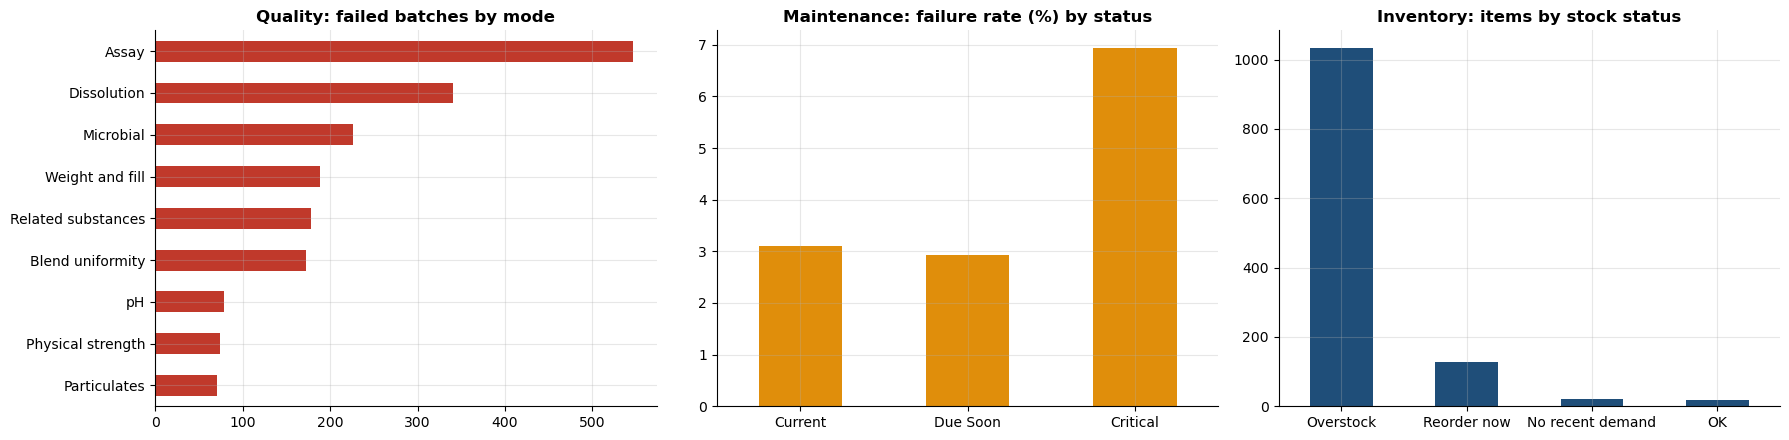

In [559]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))                             # one chart per area
batches.loc[batches[TARGET_COL] == 1, "failure_mode"].value_counts().sort_values().plot.barh(ax=ax[0], color=ALERT)
ax[0].set_title("Quality: failed batches by mode")                          # where failures come from
(100 * batches.groupby("maintenance_status")[TARGET_COL].mean()).loc[["Current", "Due Soon", "Critical"]].plot.bar(ax=ax[1], color=ACCENT, rot=0)
ax[1].set_title("Maintenance: failure rate (%) by status")                  # the maintenance effect
policy["status"].value_counts().plot.bar(ax=ax[2], color=PRIMARY, rot=0)   # stock actions
ax[2].set_title("Inventory: items by stock status")
for a in ax:                                                                # remove axis labels
    a.set_xlabel(""); a.set_ylabel("")
plt.tight_layout(); plt.show()                                              # display the charts

**Charts:** left, failed batches by mode, where Assay (546) and Dissolution (341) are the longest bars. Middle, the failure rate by maintenance status: Critical (6.9%) stands at more than double Current (3.1%) and Due Soon (2.9%). Right, items by stock status, where Overstock (1,033) far outweighs Reorder now (128).

## 5.5 Recommendations

In [562]:
actions = pd.DataFrame([
    ["High", "QA / CAPA", "Corrective action on assay and dissolution failures, starting with Oral Solids", "47% of failures"],
    ["High", "Engineering", "Service equipment before it becomes Critical", "Odds of failure 2.3x on overdue equipment"],
    ["High", "Procurement", "Buy to the reorder-point policy; stop receipts for overstocked items, especially Equipment", "Receipts about 2x sales"],
    ["Medium", "Branch stores", "Weekly reorder list and stock-out watch-list", "Catches 80% of stock-outs"],
    ["Medium", "Planning", "Plan monthly volumes with Holt-Winters and weekly product demand with the chosen weekly model", "34% / ~20% better than baseline"],
    ["Medium", "Finance", "Review credit-account terms and collections", "All unpaid balances are on credit accounts"],
    ["Low", "QA", "Use the risk tier only to target extra in-process checks", "Top 10% fail at 1.7x the average"],
], columns=["Priority", "Owner", "Action", "Evidence"])                     # one row per action
display(actions)                                                            # show the table

,Priority,Owner,Action,Evidence
0,High,QA / CAPA,"Corrective action on assay and dissolution failures, starting with Oral Solids",47% of failures
1,High,Engineering,Service equipment before it becomes Critical,Odds of failure 2.3x on overdue equipment
2,High,Procurement,"Buy to the reorder-point policy; stop receipts for overstocked items, especi...",Receipts about 2x sales
3,Medium,Branch stores,Weekly reorder list and stock-out watch-list,Catches 80% of stock-outs
4,Medium,Planning,Plan monthly volumes with Holt-Winters and weekly product demand with the ch...,34% / ~20% better than baseline
5,Medium,Finance,Review credit-account terms and collections,All unpaid balances are on credit accounts
6,Low,QA,Use the risk tier only to target extra in-process checks,Top 10% fail at 1.7x the average


## 5.6 Limitations
- **No opening stock, expiry dates, purchase-order dates or supplier lead times.** Stock is rebuilt from zero in 2014, and the reorder points assume a 14-day lead time.
- **Batches cannot be linked to sales.** No key connects them, so production and sales are compared by month only.
- **Optimistic scores:** the random split in the maintenance-status model may score higher than they would on future months. The batch classifier and the weekly models use time-ordered splits.
- **No savings claimed:** stock values should be confirmed with the stores team before any write-down.